# Infrastructure as Code: Terraform, OpenTofu, Pulumi and Friends

> **Who is this for:** AI engineers, ML engineers and anyone who has clicked around a cloud console to create a GPU cluster and now wants to do it properly: reviewed, repeatable and safe.
>
> **What you will learn:**
> - the core ideas of **Infrastructure as Code (IaC)**: declarative vs imperative, desired state, idempotency, drift, mutable vs immutable infrastructure
> - **Terraform / OpenTofu in depth**: providers, resources, data sources, variables, outputs, locals, the dependency graph, `plan` / `apply` / `destroy`, state and remote backends with locking, modules and the registry, workspaces and environments, `count` vs `for_each`, lifecycle rules, custom conditions, `import`, `moved` and `removed` blocks, `terraform test`
> - **policy as code** (Sentinel, OPA/Rego, Checkov, Trivy), **secrets in IaC** (sensitive, ephemeral and write-only values, Vault), and **cost in pull requests** (Infracost)
> - how teams run IaC: **HCP Terraform** (formerly Terraform Cloud), Terragrunt, Atlantis, Spacelift, env0
> - the **OpenTofu** fork and how it differs, **Pulumi** (IaC in Python), **CloudFormation / CDK**, **Bicep**, **Crossplane** (Kubernetes-native IaC) and Google **Infrastructure Manager**
> - a full worked example: an **AI API stack** (network, Kubernetes cluster, GPU node pool, model bucket, secrets, container service, monitoring) in HCL and in Pulumi Python
> - **runnable toys** you can poke at: a mini HCL parser -> dependency graph -> parallel apply order, a plan engine with create / update / replace / destroy, state locking and lost updates, drift detection, `count` vs `for_each`, `moved` blocks, a version-constraint solver, a policy-as-code checker, a state secret scanner and a cost diff
> - a map of the **Terraform Associate (004)** exam objectives to sections of this notebook
>
> **Prerequisites:** [Git basics](01_git_basics.ipynb), [GitHub Actions CI/CD](03_github_actions_cicd.ipynb). Helpful: the short IaC intro and toy plan/apply engine in [Distributed systems and architecture patterns, section 10](../22_ML_System_Design/10_distributed_systems_and_architecture_patterns.ipynb) (this notebook goes much deeper), [Helm and GitOps](../17_Docker/03_helm_and_gitops.ipynb), [Security for AI applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb).
>
> **Time needed:** about 3-4 hours to read and play (the code runs in a few seconds).
>
> **Runs on:** CPU, no API key, no internet, no cloud account. Real Terraform / Pulumi / cloud code is shown in markdown blocks only; everything you run is a small pure-Python simulation.

**Next notebook:** [DevSecOps, CI/CD, supply chain and platform engineering](07_devsecops_cicd_supply_chain_and_platform_engineering.ipynb).

### Contents
0. Setup
1. What IaC is and the ideas behind it
2. The IaC tool landscape (and a cloud service map)
3. The Terraform language: providers, resources, data sources, variables, outputs, locals
4. The dependency graph (toy: mini HCL -> graph -> parallel apply order)
5. The core workflow: init, validate, fmt, plan, apply, destroy (toy: a plan engine)
6. State, remote backends and locking (toy: lost updates and locks)
7. Drift detection (toy)
8. `count` vs `for_each` (toy: why keys beat indexes)
9. Lifecycle rules and custom conditions
10. Refactoring and adopting resources: `import`, `moved`, `removed`, `terraform query`
11. Modules, the registry and version constraints (toy: a constraint solver)
12. Environments: workspaces, directories, Terragrunt, HCP Terraform workspaces and projects
13. Testing IaC: `terraform test` and friends
14. Policy as code: Sentinel, OPA, Checkov, Trivy (toy: a policy checker)
15. Secrets in IaC (toy: a state secret scanner)
16. Cost in pull requests: Infracost (toy: a cost diff)
17. Running IaC as a team: HCP Terraform, Atlantis, Spacelift, env0, Terragrunt
18. OpenTofu: the open-source fork and how it differs
19. Pulumi: IaC in Python
20. CloudFormation, CDK, Bicep, Infrastructure Manager, Crossplane, Ansible, Packer
21. Full worked example: an AI API stack in HCL and Pulumi Python
22. How to try it for real
23. Terraform Associate (004) objectives map and other certifications
24. Recap, interview questions, further reading

## 0. Setup

Only the standard library, pandas and matplotlib. We fix a random seed so every run prints the same numbers.

In [1]:
import re, json, copy, math, random, hashlib, itertools, textwrap
from collections import defaultdict, Counter
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
print("ready")

ready


## 1. What IaC is and the ideas behind it

**What it is:** **Infrastructure as Code (IaC)** means you describe your cloud resources (networks, Kubernetes clusters, GPU node pools, buckets, databases, permissions, alerts) in **text files** stored in Git, and a tool creates or changes the real resources so they match the files.

**Simple analogy:** an architect's blueprint. Builders follow the blueprint, inspectors can review it before anything is built, and you can build the same house again on another street (another region or environment).

**Why it matters for AI systems:** GPU capacity is expensive, model buckets hold valuable artifacts, and agents often get cloud permissions. IaC makes all of this **reviewable** (pull requests), **repeatable** (staging really looks like production), **auditable** (Git history says who changed what and why) and **recoverable** (rebuild a region from code).

### 1.1 Declarative vs imperative

| | Imperative | Declarative |
|---|---|---|
| You write | the **steps** ("create a bucket, then turn on versioning") | the **end result** ("a bucket named X with versioning on") |
| Running it twice | may fail or create a duplicate | changes nothing the second time |
| Examples | shell scripts with `aws` / `gcloud` / `az`, SDK scripts, many Ansible tasks | Terraform / OpenTofu HCL, CloudFormation, Bicep, Kubernetes manifests, Crossplane |
| Mixed | Pulumi and CDK: you write real code (loops, functions), but the code **builds a declarative desired state** that an engine compares and applies | |

### 1.2 Key words (each in one sentence)
- **Desired state:** what your code says should exist.
- **Actual state:** what really exists in the cloud right now.
- **Reconcile:** compare desired and actual, then make the smallest set of changes to close the gap.
- **Idempotent:** running the same thing again gives the same result and makes no extra changes.
- **Drift:** the real world changed without going through the code (for example, someone edited a setting in the console during an incident).
- **Mutable infrastructure:** you change servers in place (patch them, edit config files).
- **Immutable infrastructure:** you never patch in place; you build a new image or resource and replace the old one (containers, golden VM images built by Packer).
- **Provisioning vs configuration management:** provisioning creates the resources (Terraform), configuration management sets up software *inside* machines (Ansible, Chef, Puppet, Salt). Container images and Kubernetes have reduced the need for the second kind.

Let us see idempotency in code. The imperative script blindly runs its steps; the declarative reconciler compares first.

In [2]:
# A pretend cloud: a dict of resource name -> settings.
cloud = {}

def imperative_script(cloud):
    # "Do these steps." It does not look at what already exists.
    name = f"bucket-{len(cloud) + 1}"          # a naive script often generates names like this
    cloud[name] = {"versioning": False}
    cloud[name]["versioning"] = True           # step 2: turn on versioning
    return f"created {name}"

def declarative_reconcile(cloud, desired):
    # "Make the world look like this." It compares first, then changes only the gaps.
    changes = []
    for name, settings in desired.items():
        if name not in cloud:
            cloud[name] = dict(settings); changes.append(f"create {name}")
        elif cloud[name] != settings:
            cloud[name] = dict(settings); changes.append(f"update {name}")
    return changes or ["no changes"]

print("Imperative, run 3 times:")
for _ in range(3): print("  ", imperative_script(cloud))
print("   cloud now has", len(cloud), "buckets (we wanted 1!)")

cloud = {}
desired = {"model-artifacts": {"versioning": True}}
print("\nDeclarative, run 3 times:")
for _ in range(3): print("  ", declarative_reconcile(cloud, desired))
print("   cloud now has", len(cloud), "bucket")

Imperative, run 3 times:
   created bucket-1
   created bucket-2
   created bucket-3
   cloud now has 3 buckets (we wanted 1!)

Declarative, run 3 times:
   ['create model-artifacts']
   ['no changes']
   ['no changes']
   cloud now has 1 bucket


**When to use IaC:** for anything that lives longer than an afternoon experiment, and always for production. **When not to:** a quick throw-away exploration in a sandbox account (then delete it). And the golden rule: **once a resource is managed by IaC, change it only through IaC**, otherwise drift will surprise you later (section 7).

## 2. The IaC tool landscape (and a cloud service map)

| Tool | Language | Clouds | State lives in | Notes (as of late 2026) |
|---|---|---|---|---|
| **Terraform** (HashiCorp, part of IBM since 2025) | HCL | any (thousands of providers) | state file in a backend (local, S3, GCS, Azure Blob, HCP Terraform...) | Business Source License (BSL) since Aug 2023. Recent: 1.14 (Nov 2025) added list resources, `terraform query` and `action` blocks; 1.15 (Apr 2026) added dynamic module sources and variable deprecation |
| **OpenTofu** (Linux Foundation) | HCL | any (same providers) | same as Terraform | open-source (MPL-2.0) fork of Terraform 1.5.x; adds state encryption, `enabled` meta-argument and more (section 18) |
| **Pulumi** | Python, TypeScript, Go, C#, Java, YAML | any | Pulumi Cloud or a self-managed backend (S3, GCS, Azure Blob, local) | real programming languages; Pulumi ESC for secrets/config; Neo AI agent |
| **AWS CloudFormation** | YAML / JSON | AWS | managed by AWS (stacks) | change sets, drift detection, StackSets |
| **AWS CDK** | TypeScript, Python, Java, C#, Go | AWS | CloudFormation | code that **synthesizes** CloudFormation templates |
| **Bicep** | Bicep DSL (compiles to ARM JSON) | Azure | managed by Azure (deployments, deployment stacks) | `what-if` preview |
| **Google Infrastructure Manager** | Terraform HCL | Google Cloud | managed by Google | managed Terraform runs; replaces the discontinued Cloud Deployment Manager (2026) |
| **Crossplane** (CNCF) | Kubernetes YAML + composition functions | any | the Kubernetes API (etcd) | continuous reconciliation like any Kubernetes controller |
| **CDK for Terraform (CDKTF)** | TS, Python... | any | Terraform state | **deprecated and archived by HashiCorp on 10 Dec 2025**; export to HCL with `cdktf synth --hcl` or move to Pulumi |
| **Ansible** | YAML playbooks | any | none (mostly stateless) | configuration management; can provision, but has no plan/state like Terraform |

### Service map: the managed IaC services each cloud offers

| Need | AWS | Azure | Google Cloud |
|---|---|---|---|
| Native IaC language | CloudFormation (YAML/JSON) | ARM templates / **Bicep** | Infrastructure Manager (runs Terraform); Deployment Manager is discontinued |
| IaC in a programming language | AWS CDK | (Bicep is a DSL; Pulumi / Terraform are common) | (Terraform / Pulumi) |
| Preview a change | change sets | `what-if` | Terraform plan (preview in Infra Manager) |
| Drift detection | CloudFormation drift detection | deployment stacks + `what-if` | Terraform plan / refresh |
| Deploy to many accounts/regions | StackSets | deployment stacks at management-group scope | Terraform with many workspaces / folders |
| Managed Terraform state | (S3 bucket backend) | (Azure Blob backend) | (GCS backend), Infra Manager |
| Service catalog of approved templates | AWS Service Catalog | Azure template specs, managed applications | Service Catalog (Google Cloud) |

**How to pick (simple rule of thumb):** multi-cloud or many SaaS providers (Datadog, GitHub, Cloudflare...) -> Terraform or OpenTofu. Your team prefers real code and testing in Python -> Pulumi. AWS-only shop with deep CloudFormation investment -> CDK. Azure-only -> Bicep or Terraform. Platform team building self-service APIs on Kubernetes -> Crossplane.

## 3. The Terraform language: providers, resources, data sources, variables, outputs, locals

Terraform files end in `.tf` and use **HCL** (HashiCorp Configuration Language). All `.tf` files in one folder form one **root module**. Everything below works the same in OpenTofu (`tofu` instead of `terraform`).

### 3.1 Providers

**What it is:** a **provider** is a plugin that knows how to talk to one API (AWS, Google Cloud, Azure, Kubernetes, GitHub, Datadog...). **Analogy:** a power adapter for each country's sockets. **How it works:** `terraform init` downloads the providers you list from the registry and records their exact versions and checksums in `.terraform.lock.hcl` (commit that file).

```hcl
terraform {
  required_version = ">= 1.10"
  required_providers {
    google = {
      source  = "hashicorp/google"   # registry address: <namespace>/<name>
      version = "~> 7.0"             # any 7.x (check the registry for the current major)
    }
    random = { source = "hashicorp/random", version = "~> 3.6" }
  }
}

provider "google" {
  project = var.project_id
  region  = var.region
}

# A second configuration of the same provider, selected with an alias
provider "google" {
  alias  = "us"
  region = "us-central1"
}
```

### 3.2 Resources and data sources

- A **resource** block = something Terraform **creates and manages** (a bucket, a node pool).
- A **data source** block = something Terraform only **reads** (an existing network, the latest image, the current project). It never creates or deletes anything.

```hcl
data "google_project" "current" {}                      # read-only lookup

resource "google_storage_bucket" "models" {             # <TYPE> <LOCAL NAME>
  name     = "${data.google_project.current.project_id}-models"
  location = var.region
  versioning { enabled = true }                         # a nested block
}

resource "google_storage_bucket" "eval_us" {
  provider = google.us                                  # use the aliased provider
  name     = "${data.google_project.current.project_id}-evals-us"
  location = "US"
}
```

The **address** of a resource is `TYPE.NAME`, for example `google_storage_bucket.models`. Other blocks refer to its **attributes** like `google_storage_bucket.models.url`. That reference is also how Terraform learns the order of creation (section 4).

### 3.3 Variables, outputs and locals

| Block | What it is | Analogy |
|---|---|---|
| `variable` | an **input** to the module | a function parameter |
| `output` | a value the module **returns** (shown after apply, readable by other modules or `terraform_remote_state`) | a function return value |
| `locals` | a **named expression** inside the module, to avoid repeating yourself | a local variable |

```hcl
variable "env" {
  type        = string
  description = "Deployment environment"
  validation {                                   # custom condition (section 9)
    condition     = contains(["dev", "staging", "prod"], var.env)
    error_message = "env must be dev, staging or prod."
  }
}

variable "gpu_pools" {                           # a complex type: map of objects
  type = map(object({
    machine   = string
    gpus      = number
    max_nodes = optional(number, 2)              # optional attribute with a default
  }))
  default = {
    small = { machine = "g2-standard-8", gpus = 1 }
    large = { machine = "a3-highgpu-8g", gpus = 8, max_nodes = 1 }
  }
}

variable "db_password" {
  type      = string
  sensitive = true                               # hidden in plan output (but see section 15!)
}

locals {
  name   = "ai-api-${var.env}"                   # string interpolation
  labels = { app = "ai-api", env = var.env }
  is_prod = var.env == "prod"
}

output "bucket_url" {
  value       = google_storage_bucket.models.url
  description = "Where model artifacts live"
}
```

Values for variables come from (lowest to highest priority): defaults, `terraform.tfvars` / `*.auto.tfvars` files, `-var-file=prod.tfvars`, `-var 'env=prod'` on the command line; environment variables `TF_VAR_env=prod` sit just above the defaults.

### 3.4 Types, expressions and functions (the short tour)
- **Types:** `string`, `number`, `bool`, `list(...)`, `set(...)`, `map(...)`, `object({...})`, `tuple([...])`, `any`.
- **Conditionals:** `local.is_prod ? 3 : 1`.
- **`for` expressions:** `[for k, p in var.gpu_pools : k if p.gpus > 1]` and `{for k, p in var.gpu_pools : k => p.machine}`.
- **Splat:** `google_compute_subnetwork.all[*].id`.
- **`dynamic` blocks:** generate repeated nested blocks from a collection.
- **Built-in functions:** `merge`, `lookup`, `coalesce`, `cidrsubnet`, `format`, `jsonencode`, `yamldecode`, `file`, `templatefile`, `try`, `can`... Try them in `terraform console`. (You cannot write your own functions in plain HCL, but providers can ship provider-defined functions.)

Python equivalents of a few common expressions, so the HCL feels familiar:

In [3]:
gpu_pools = {"small": {"machine": "g2-standard-8", "gpus": 1},
             "large": {"machine": "a3-highgpu-8g", "gpus": 8, "max_nodes": 1}}

# optional(number, 2): fill a default for a missing attribute
gpu_pools = {k: {"max_nodes": 2, **v} for k, v in gpu_pools.items()}

# [for k, p in var.gpu_pools : k if p.gpus > 1]
multi_gpu = [k for k, p in gpu_pools.items() if p["gpus"] > 1]

# {for k, p in var.gpu_pools : k => p.machine}
machines = {k: p["machine"] for k, p in gpu_pools.items()}

# merge(local.labels, { team = "ml" })
labels = {**{"app": "ai-api", "env": "prod"}, **{"team": "ml"}}

# cidrsubnet("10.0.0.0/16", 8, 2)  -> carve the 3rd /24 out of a /16
import ipaddress
def cidrsubnet(prefix, newbits, netnum):
    net = ipaddress.ip_network(prefix)
    return str(list(net.subnets(prefixlen_diff=newbits))[netnum])

print("multi_gpu :", multi_gpu)
print("machines  :", machines)
print("labels    :", labels)
print("cidrsubnet:", cidrsubnet("10.0.0.0/16", 8, 2))

multi_gpu : ['large']
machines  : {'small': 'g2-standard-8', 'large': 'a3-highgpu-8g'}
labels    : {'app': 'ai-api', 'env': 'prod', 'team': 'ml'}
cidrsubnet: 10.0.2.0/24


## 4. The dependency graph

**What it is:** Terraform reads all blocks, finds every reference like `google_compute_network.vpc.id`, and builds a **directed acyclic graph (DAG)**: an arrow from A to B means "B needs A first".

**Simple analogy:** getting dressed. Socks before shoes, shirt before jacket, but socks and shirt can happen at the same time.

**How it works:**
1. Parse the files into blocks.
2. Each reference creates an **implicit dependency**. `depends_on = [...]` adds an **explicit** one when there is no reference to follow (for example, an IAM permission that must exist before a service starts).
3. Sort the graph topologically. Everything whose dependencies are done can run **in parallel** (Terraform walks up to 10 nodes at once by default, `-parallelism=N`).
4. Destroy walks the graph in **reverse** (delete the service before the network it sits in).
5. A **cycle** (A needs B, B needs A) is an error: Terraform refuses to plan.

Let us build a tiny HCL-like parser for a simplified **AI API stack** and compute the apply order ourselves.

In [4]:
# A simplified, HCL-like config for an AI API stack. One attribute per line, no nesting,
# so our tiny parser stays short. References look exactly like Terraform: TYPE.NAME.ATTR or var.NAME.
STACK = """
variable "region" { default = "europe-west4" }
variable "max_gpu_nodes" { default = 4 }

resource "network" "vpc" {
  cidr = "10.10.0.0/16"
}
resource "subnet" "gke" {
  network = network.vpc.id
  cidr    = "10.10.0.0/20"
}
resource "cluster" "ai" {
  subnet = subnet.gke.id
  region = var.region
}
resource "node_pool" "gpu" {
  cluster   = cluster.ai.id
  machine   = "g2-standard-8"
  gpus      = 1
  max_nodes = var.max_gpu_nodes
}
resource "bucket" "models" {
  region     = var.region
  versioning = true
  public     = false
}
resource "secret" "llm_key" {
  replication = "auto"
}
resource "service_account" "api" {
  purpose = "ai-api runtime identity"
}
resource "iam_binding" "api_reads_key" {
  secret = secret.llm_key.id
  member = service_account.api.email
}
resource "service" "api" {
  cluster  = cluster.ai.id
  bucket   = bucket.models.name
  secret   = secret.llm_key.id
  identity = service_account.api.email
  image    = "europe-docker.pkg.dev/acme/ai/api@sha256:1f2e3d"
  replicas = 2
  depends_on = [iam_binding.api_reads_key, node_pool.gpu]
}
resource "alert" "latency" {
  target       = service.api.id
  threshold_ms = 2000
}
output "api_url" { value = service.api.url }
"""

BLOCK_RE = re.compile(r'(resource|variable|output|data)\s+"([^"]+)"(?:\s+"([^"]+)")?\s*\{(.*?)\}\s*$', re.S | re.M)
ATTR_RE  = re.compile(r'^\s*([a-z_0-9]+)\s*=\s*(.+?)\s*$', re.M)

def parse_value(raw):
    # Turn the right-hand side of "key = value" into a Python value.
    if raw.startswith('"'):            return raw.strip('"')                    # string
    if raw in ("true", "false"):       return raw == "true"                     # bool
    if raw.startswith("["):            return [parse_value(x.strip()) for x in raw.strip("[]").split(",") if x.strip()]
    if re.fullmatch(r"-?\d+", raw):    return int(raw)                          # number
    return {"ref": raw}                                                         # a reference expression

def parse(text):
    blocks = {}
    for kind, a, b, body in BLOCK_RE.findall(text):
        attrs = {k: parse_value(v) for k, v in ATTR_RE.findall(body)}
        addr = {"resource": f"{a}.{b}", "data": f"data.{a}.{b}",
                "variable": f"var.{a}", "output": f"output.{a}"}[kind]
        blocks[addr] = {"kind": kind, "type": a, "attrs": attrs}
    return blocks

def ref_target(ref):
    # "network.vpc.id" -> "network.vpc";  "var.region" -> "var.region";  "data.x.y.z" -> "data.x.y"
    parts = ref.split(".")
    if parts[0] == "var":  return ".".join(parts[:2])
    if parts[0] == "data": return ".".join(parts[:3])
    return ".".join(parts[:2])

def dependencies(blocks):
    deps = {}
    for addr, blk in blocks.items():
        d = set()
        for key, val in blk["attrs"].items():
            vals = val if isinstance(val, list) else [val]
            for v in vals:
                if isinstance(v, dict) and "ref" in v:
                    d.add(ref_target(v["ref"]))
        deps[addr] = d
    return deps

blocks = parse(STACK)
deps = dependencies(blocks)
for addr, d in deps.items():
    print(f"{addr:26} needs {sorted(d) if d else '-'}")

var.region                 needs -
var.max_gpu_nodes          needs -
network.vpc                needs -
subnet.gke                 needs ['network.vpc']
cluster.ai                 needs ['subnet.gke', 'var.region']
node_pool.gpu              needs ['cluster.ai', 'var.max_gpu_nodes']
bucket.models              needs ['var.region']
secret.llm_key             needs -
service_account.api        needs -
iam_binding.api_reads_key  needs ['secret.llm_key', 'service_account.api']
service.api                needs ['bucket.models', 'cluster.ai', 'iam_binding.api_reads_key', 'node_pool.gpu', 'secret.llm_key', 'service_account.api']
alert.latency              needs ['service.api']
output.api_url             needs ['service.api']


In [5]:
def waves(deps):
    # Kahn's algorithm, but we collect nodes in "waves": everything in one wave can run in parallel.
    remaining = {n: set(d) for n, d in deps.items()}
    out = []
    while remaining:
        ready = sorted(n for n, d in remaining.items() if not d)
        if not ready:
            raise ValueError(f"Cycle detected between: {sorted(remaining)}")
        out.append(ready)
        for n in ready:
            remaining.pop(n)
        for d in remaining.values():
            d.difference_update(ready)
    return out

apply_waves = waves(deps)
print("APPLY order (each line runs in parallel):")
for i, w in enumerate(apply_waves, 1):
    print(f"  wave {i}: {', '.join(w)}")

print("\nDESTROY order (reverse):")
for i, w in enumerate(reversed(apply_waves), 1):
    print(f"  wave {i}: {', '.join(x for x in w if not x.startswith(('var.', 'output.')))}")

APPLY order (each line runs in parallel):
  wave 1: network.vpc, secret.llm_key, service_account.api, var.max_gpu_nodes, var.region
  wave 2: bucket.models, iam_binding.api_reads_key, subnet.gke
  wave 3: cluster.ai
  wave 4: node_pool.gpu
  wave 5: service.api
  wave 6: alert.latency, output.api_url

DESTROY order (reverse):
  wave 1: alert.latency
  wave 2: service.api
  wave 3: node_pool.gpu
  wave 4: cluster.ai
  wave 5: bucket.models, iam_binding.api_reads_key, subnet.gke
  wave 6: network.vpc, secret.llm_key, service_account.api


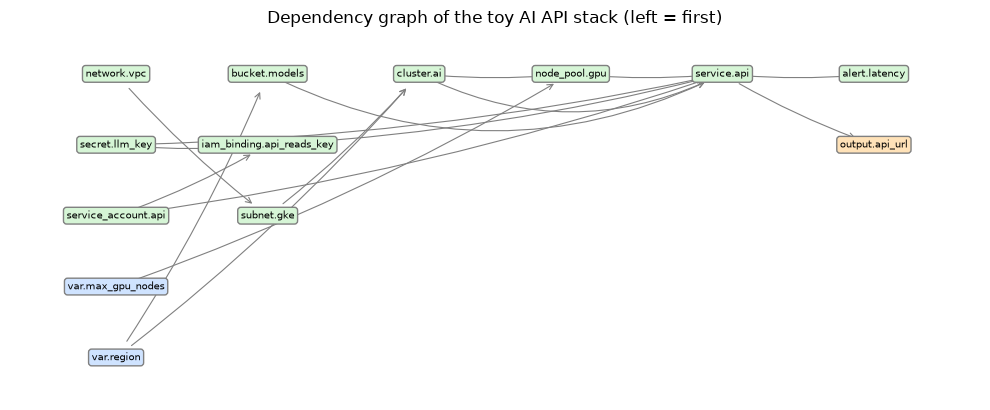

In [6]:
# Draw the graph: x = wave number, arrows point from a dependency to the block that needs it.
pos = {}
for x, w in enumerate(apply_waves):
    for y, n in enumerate(w):
        pos[n] = (x, -y)

fig, ax = plt.subplots(figsize=(10, 4.2))
for n, d in deps.items():
    for src in d:
        (x1, y1), (x2, y2) = pos[src], pos[n]
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="->", color="gray", lw=0.8, shrinkA=14, shrinkB=14,
                                    connectionstyle="arc3,rad=0.25" if y1 == y2 and abs(x2 - x1) > 1 else "arc3,rad=0.05"))
for n, (x, y) in pos.items():
    color = "#cfe3ff" if n.startswith("var.") else ("#ffe2b8" if n.startswith("output.") else "#d6f5d6")
    ax.text(x, y, n, ha="center", va="center", fontsize=7.5,
            bbox=dict(boxstyle="round", fc=color, ec="gray"))
ax.set_xlim(-0.7, len(apply_waves) - 0.3); ax.set_ylim(-max(len(w) for w in apply_waves) + 0.4, 0.6); ax.axis("off")
ax.set_title("Dependency graph of the toy AI API stack (left = first)")
plt.tight_layout(); plt.show()

In [7]:
# What happens with a cycle? The service needs the alert, and the alert needs the service.
bad = copy.deepcopy(deps)
bad["service.api"].add("alert.latency")
try:
    waves(bad)
except ValueError as e:
    print("terraform plan would fail like this ->", e)

terraform plan would fail like this -> Cycle detected between: ['alert.latency', 'output.api_url', 'service.api']


**What just happened?** References alone gave us the whole order. The network, secret and service account have no dependencies, so they start together in wave 1. (Variables are graph nodes too, which is why the bucket, needing only `var.region`, lands in wave 2; real Terraform evaluates variables instantly, so in practice it starts at once.) The service waits for the cluster, the IAM binding and (through `depends_on`) the GPU node pool. Real Terraform prints this graph with `terraform graph` (DOT format, view it with Graphviz).

**When to use `depends_on`:** only for hidden dependencies that no reference expresses. Overusing it makes plans slower and more "known after apply" values appear, because Terraform has to wait for the whole upstream resource.

## 5. The core workflow: init, validate, fmt, plan, apply, destroy

```mermaid
flowchart LR
  W[Write .tf code] --> I[terraform init<br/>download providers & modules,<br/>configure backend]
  I --> F[terraform fmt<br/>terraform validate]
  F --> P[terraform plan<br/>refresh + diff]
  P --> R{Human / policy<br/>review}
  R -- approve --> A[terraform apply<br/>execute the saved plan]
  R -- reject --> W
  A --> S[(state updated)]
  S --> P
```

| Command | What it does |
|---|---|
| `terraform init` | downloads providers and modules, sets up the backend; run it first and after changing providers/modules/backend (`-upgrade` to pick newer allowed versions) |
| `terraform fmt` | rewrites files into the standard style (`-check` in CI fails if not formatted) |
| `terraform validate` | checks syntax and internal consistency, without calling cloud APIs |
| `terraform plan` | refreshes the state from the real cloud, then shows the diff; `-out=tfplan` saves it so apply runs exactly what was reviewed |
| `terraform apply` | executes a plan (asks for `yes` unless given a saved plan or `-auto-approve`) |
| `terraform destroy` | deletes everything in this state (same as `apply -destroy`) |
| `terraform plan -refresh-only` | only shows drift between state and reality (section 7) |
| `terraform plan -replace=ADDR` | force one resource to be replaced (the old `taint` command is deprecated) |
| `terraform show -json tfplan` | the plan as JSON, which policy tools read (section 14) |
| `terraform output`, `terraform console`, `terraform graph`, `terraform state ...` | inspect |

**Reading a plan.** The symbols matter:

| Symbol | Meaning | Risk |
|---|---|---|
| `+` | create | low |
| `~` | update in place | low to medium |
| `-/+` | **replace**: destroy then create (a "force new" attribute changed, like a bucket's region or a node pool's machine type) | **high**: data or IPs may be lost, downtime |
| `+/-` | replace with `create_before_destroy` (new one first) | medium |
| `-` | destroy | **high** |
| `<=` | read a data source | none |
| `(known after apply)` | value only known once the upstream resource exists | - |

Below is a toy **plan engine** for our stack. Compared with the small engine in notebook 22/10, it adds: per-type "force new" attributes, `(known after apply)` values that **propagate** replacements down the graph, `prevent_destroy`, `ignore_changes`, `create_before_destroy`, and ordered destroys.

In [8]:
# Which attributes force a replacement when they change ("ForceNew" in provider schemas).
FORCE_NEW = {
    "network": {"cidr"}, "subnet": {"network", "cidr"}, "cluster": {"subnet", "region"},
    "node_pool": {"cluster", "machine", "gpus"}, "bucket": {"region"},
    "secret": {"replication"}, "service_account": set(), "iam_binding": {"secret", "member"},
    "service": {"cluster"}, "alert": {"target"},
}
UNKNOWN = "(known after apply)"
VARS = {k[4:]: b["attrs"]["default"] for k, b in blocks.items() if b["kind"] == "variable"}

def resolve(value, state, variables, pending):
    # Replace references with real values from state, or UNKNOWN if the target will be (re)created.
    if isinstance(value, list):
        return [resolve(v, state, variables, pending) for v in value]
    if not (isinstance(value, dict) and "ref" in value):
        return value
    ref = value["ref"]; target = ref_target(ref); attr = ref.split(".")[-1]
    if target.startswith("var."):
        return variables[target[4:]]
    if target in pending or target not in state:
        return UNKNOWN
    return state[target]["computed"].get(attr, state[target]["attrs"].get(attr))

def resource_order(blocks):
    flat = [a for w in waves(dependencies(blocks)) for a in w]
    return [a for a in flat if blocks[a]["kind"] == "resource"]

def plan(blocks, state, variables, lifecycle=None):
    lifecycle = lifecycle or {}
    changes, pending = [], set()          # pending = resources that will get NEW ids in this run
    for addr in resource_order(blocks):
        lc = lifecycle.get(addr, {})
        want = {k: resolve(v, state, variables, pending) for k, v in blocks[addr]["attrs"].items()
                if k != "depends_on"}
        if addr not in state:
            changes.append({"action": "create", "addr": addr, "after": want}); pending.add(addr); continue
        have = state[addr]["attrs"]
        diff = {k: (have.get(k), v) for k, v in want.items()
                if have.get(k) != v and k not in lc.get("ignore_changes", [])}
        if not diff:
            continue
        forced = sorted(set(diff) & FORCE_NEW[blocks[addr]["type"]])
        if forced:
            action = "replace_cbd" if lc.get("create_before_destroy") else "replace"
            changes.append({"action": action, "addr": addr, "diff": diff, "forced_by": forced}); pending.add(addr)
        else:
            changes.append({"action": "update", "addr": addr, "diff": diff})
    # resources in state but not in code -> destroy, dependents first
    gone = [a for a in state if a not in blocks]
    gone_deps = {a: state[a]["deps"] & set(gone) for a in gone}
    for w in reversed(waves(gone_deps)):
        for a in w:
            changes.append({"action": "delete", "addr": a})
    # prevent_destroy is checked at PLAN time: Terraform refuses to even produce the plan
    for ch in changes:
        if ch["action"] in ("delete", "replace", "replace_cbd") and lifecycle.get(ch["addr"], {}).get("prevent_destroy"):
            raise RuntimeError(f"Error: Instance cannot be destroyed: {ch['addr']} has lifecycle.prevent_destroy = true")
    return changes

SYMBOL = {"create": "  +", "update": "  ~", "replace": "-/+", "replace_cbd": "+/-", "delete": "  -"}
def show_plan(changes):
    if not changes:
        print("No changes. Your infrastructure matches the configuration."); return
    for ch in changes:
        line = f"{SYMBOL[ch['action']]} {ch['addr']}"
        if ch["action"] == "create":
            line += "   " + ", ".join(f"{k}={v}" for k, v in ch["after"].items())
        elif ch["action"] != "delete":
            line += "   " + ", ".join(f"{k}: {o} -> {n}" for k, (o, n) in ch["diff"].items())
            if "forced_by" in ch: line += f"   # forces replacement ({', '.join(ch['forced_by'])})"
        print(line)
    add = sum(c["action"] in ("create", "replace", "replace_cbd") for c in changes)
    chg = sum(c["action"] == "update" for c in changes)
    dele = sum(c["action"] in ("delete", "replace", "replace_cbd") for c in changes)
    print(f"\nPlan: {add} to add, {chg} to change, {dele} to destroy.")

state = {}
first = plan(blocks, state, VARS)
show_plan(first)

  + network.vpc   cidr=10.10.0.0/16
  + secret.llm_key   replication=auto
  + service_account.api   purpose=ai-api runtime identity
  + bucket.models   region=europe-west4, versioning=True, public=False
  + iam_binding.api_reads_key   secret=(known after apply), member=(known after apply)
  + subnet.gke   network=(known after apply), cidr=10.10.0.0/20
  + cluster.ai   subnet=(known after apply), region=europe-west4
  + node_pool.gpu   cluster=(known after apply), machine=g2-standard-8, gpus=1, max_nodes=4
  + service.api   cluster=(known after apply), bucket=(known after apply), secret=(known after apply), identity=(known after apply), image=europe-docker.pkg.dev/acme/ai/api@sha256:1f2e3d, replicas=2
  + alert.latency   target=(known after apply), threshold_ms=2000

Plan: 10 to add, 0 to change, 0 to destroy.


In [9]:
_ids = itertools.count(1001)
def apply(changes, blocks, state, cloud, variables, verbose=True):
    log = (lambda *a: print("  ", *a)) if verbose else (lambda *a: None)
    def create(addr):
        typ = blocks[addr]["type"]
        attrs = {k: resolve(v, state, variables, set()) for k, v in blocks[addr]["attrs"].items() if k != "depends_on"}
        rid = f"{typ}-{next(_ids)}"
        name = addr.split(".")[1]
        computed = {"id": rid, "name": f"{name}-{rid[-4:]}"}
        if typ == "service_account": computed["email"] = f"{name}@acme.iam.example"
        if typ == "service":         computed["url"] = f"https://{name}.example.internal"
        cloud[rid] = {"type": typ, "attrs": copy.deepcopy(attrs)}
        state[addr] = {"attrs": attrs, "computed": computed,
                       "deps": {d for d in dependencies({addr: blocks[addr]})[addr] if not d.startswith("var.")}}
        log(f"{addr}: Creation complete [id={rid}]")
    def delete(addr):
        rid = state[addr]["computed"]["id"]; cloud.pop(rid, None); state.pop(addr)
        log(f"{addr}: Destruction complete [id={rid}]")
    for ch in changes:
        a, addr = ch["action"], ch["addr"]
        if a == "create":   create(addr)
        elif a == "delete": delete(addr)
        elif a == "update":
            rid = state[addr]["computed"]["id"]
            for k, (_, new) in ch["diff"].items():
                new = resolve(blocks[addr]["attrs"][k], state, variables, set())
                cloud[rid]["attrs"][k] = new; state[addr]["attrs"][k] = new
            log(f"{addr}: Modifications complete [id={rid}]")
        elif a == "replace":          # default: destroy first -> a gap where nothing exists
            delete(addr); log(f"{addr}: (gap: no resource exists right now)"); create(addr)
        elif a == "replace_cbd":      # create_before_destroy: new one first, then delete old
            old = state[addr]["computed"]["id"]; create(addr)
            cloud.pop(old, None); log(f"{addr}: old object {old} destroyed after the new one was ready")
    print(f"Apply complete! Resources: {sum(c['action']!='update' and c['action']!='delete' for c in changes)} added/replaced, "
          f"{sum(c['action']=='update' for c in changes)} changed, {sum(c['action']=='delete' for c in changes)} destroyed.")

cloud = {}
apply(first, blocks, state, cloud, VARS)
print("\nSecond plan (idempotency check):")
show_plan(plan(blocks, state, VARS))

   network.vpc: Creation complete [id=network-1001]
   secret.llm_key: Creation complete [id=secret-1002]
   service_account.api: Creation complete [id=service_account-1003]
   bucket.models: Creation complete [id=bucket-1004]
   iam_binding.api_reads_key: Creation complete [id=iam_binding-1005]
   subnet.gke: Creation complete [id=subnet-1006]
   cluster.ai: Creation complete [id=cluster-1007]
   node_pool.gpu: Creation complete [id=node_pool-1008]
   service.api: Creation complete [id=service-1009]
   alert.latency: Creation complete [id=alert-1010]
Apply complete! Resources: 10 added/replaced, 0 changed, 0 destroyed.

Second plan (idempotency check):
No changes. Your infrastructure matches the configuration.


In [10]:
# Change 1: raise the GPU autoscaling limit (an in-place update).
VARS2 = dict(VARS, max_gpu_nodes=8)
print("== Change max_gpu_nodes 4 -> 8")
show_plan(plan(blocks, state, VARS2))

# Change 2: a new subnet CIDR. Watch the replacement RIPPLE down the graph:
# subnet gets a new id -> cluster.subnet is unknown -> cluster replaced -> node_pool and service too.
blocks_cidr = copy.deepcopy(blocks)
blocks_cidr["subnet.gke"]["attrs"]["cidr"] = "10.10.16.0/20"
print("\n== Change the subnet CIDR")
show_plan(plan(blocks_cidr, state, VARS))

== Change max_gpu_nodes 4 -> 8
  ~ node_pool.gpu   max_nodes: 4 -> 8

Plan: 0 to add, 1 to change, 0 to destroy.

== Change the subnet CIDR
-/+ subnet.gke   cidr: 10.10.0.0/20 -> 10.10.16.0/20   # forces replacement (cidr)
-/+ cluster.ai   subnet: subnet-1006 -> (known after apply)   # forces replacement (subnet)
-/+ node_pool.gpu   cluster: cluster-1007 -> (known after apply)   # forces replacement (cluster)
-/+ service.api   cluster: cluster-1007 -> (known after apply)   # forces replacement (cluster)
-/+ alert.latency   target: service-1009 -> (known after apply)   # forces replacement (target)

Plan: 5 to add, 0 to change, 5 to destroy.


In [11]:
# Change 3: someone deletes the bucket block from the code by mistake.
LIFECYCLE = {"bucket.models": {"prevent_destroy": True}}
blocks_nobucket = copy.deepcopy(blocks)
blocks_nobucket.pop("bucket.models")
# (the service referenced the bucket, so drop that attribute too for this demo)
blocks_nobucket["service.api"]["attrs"].pop("bucket")
print("== Without prevent_destroy:")
show_plan(plan(blocks_nobucket, state, VARS))
print("\n== With lifecycle { prevent_destroy = true } on the bucket:")
try:
    plan(blocks_nobucket, state, VARS, LIFECYCLE)
except RuntimeError as e:
    print(e)

== Without prevent_destroy:
  - bucket.models

Plan: 0 to add, 0 to change, 1 to destroy.

== With lifecycle { prevent_destroy = true } on the bucket:
Error: Instance cannot be destroyed: bucket.models has lifecycle.prevent_destroy = true


**What just happened?**
- The first plan created 10 resources; the second plan was **empty**. That is idempotency.
- Raising `max_gpu_nodes` was a safe in-place update (`~`).
- Changing one subnet CIDR replaced the subnet, which gave it a **new id**, which made the cluster's `subnet` input `(known after apply)`, which forced the cluster, then the GPU pool and the service to be replaced. One innocent-looking line can rebuild half the stack. **Always read the plan, especially every `-/+` and `-` line.**
- `prevent_destroy` turned a silent data-loss plan into an error. In real Terraform you also protect data with cloud-side settings (bucket retention, `deletion_protection` on clusters and databases).

**Good habits:** in CI, run `plan -out=tfplan`, post the plan to the pull request, have a human (and a policy engine) approve, then `apply tfplan` so exactly the reviewed plan runs. Never `apply -auto-approve` straight from a laptop to production.

## 6. State, remote backends and locking

### 6.1 What the state file is
**What it is:** `terraform.tfstate` is a JSON file where Terraform records **which real object belongs to which address** (`google_storage_bucket.models` -> bucket `acme-models`) plus every attribute it last saw, the dependencies, a `serial` number (increases on every write) and a `lineage` (a unique id for this state's history).

**Simple analogy:** the inventory list of a warehouse. Without it, Terraform cannot know that bucket `acme-models` is "its" bucket, so it would try to create a second one.

**Why it is sensitive:** state contains **every attribute**, including generated passwords, private keys and connection strings, in plain text. Treat state like a secret (section 15).

### 6.2 Backends
A **backend** decides where state lives. The default **local backend** writes `terraform.tfstate` in the folder, which is fine for learning and wrong for teams.

```hcl
# AWS: S3 with native lock files (Terraform 1.10+). The older DynamoDB lock table is deprecated.
terraform {
  backend "s3" {
    bucket       = "acme-tfstate"
    key          = "ai-api/prod/terraform.tfstate"
    region       = "eu-west-1"
    encrypt      = true
    use_lockfile = true
  }
}

# Google Cloud: GCS (locking is built in)
terraform {
  backend "gcs" {
    bucket = "acme-tfstate"
    prefix = "ai-api/prod"
  }
}

# Azure: Blob Storage (locking uses blob leases)
terraform {
  backend "azurerm" {
    resource_group_name  = "rg-tfstate"
    storage_account_name = "acmetfstate"
    container_name       = "tfstate"
    key                  = "ai-api/prod.tfstate"
    use_azuread_auth     = true
  }
}

# HCP Terraform: state, locking, runs and policies managed for you
terraform {
  cloud {
    organization = "acme"
    workspaces { name = "ai-api-prod" }
  }
}
```

Best practices: one state per environment and per "blast radius" (network separate from apps); turn on **bucket versioning** so you can recover an older state; restrict who can read the bucket; never commit `*.tfstate` to Git.

Useful commands: `terraform state list`, `state show ADDR`, `state mv` (prefer `moved` blocks now), `state rm` (prefer `removed` blocks), `state pull` / `push` (dangerous), `force-unlock LOCK_ID`.

### 6.3 Why locking matters: the lost update
Two CI jobs run `apply` against the same state at the same time. Both read serial 5, both add a resource, both write. The second write **overwrites** the first, and the first job's resource now exists in the cloud but not in state: an **orphan** nobody manages (and pays for).

In [12]:
class RemoteBackend:
    # A toy remote backend: holds one state document and an optional lock.
    def __init__(self):
        self.doc = {"serial": 5, "lineage": "7c1d-ai-api-prod", "resources": {"bucket.models": "bucket-1001"}}
        self.lock = None
    def read(self):
        return copy.deepcopy(self.doc)
    def write(self, new_doc, who, check_serial=True):
        if check_serial and new_doc["serial"] != self.doc["serial"] + 1:
            raise RuntimeError(f"{who}: refusing to write: my changes are based on serial {new_doc['serial'] - 1}, "
                               f"but the state is already at serial {self.doc['serial']} -> run plan again")
        self.doc = new_doc

cloud_ids = {"bucket-1001"}

def ci_job(backend, who, new_addr, new_id, check_serial):
    doc = backend.read()                         # 1. read state
    cloud_ids.add(new_id)                        # 2. create the real resource
    doc["resources"][new_addr] = new_id          # 3. record it
    doc["serial"] += 1
    return lambda: backend.write(doc, who, check_serial)   # 4. write later (we control timing)

print("== Without locking and without serial checks")
be = RemoteBackend()
w1 = ci_job(be, "job-A", "node_pool.gpu", "np-2001", check_serial=False)
w2 = ci_job(be, "job-B", "alert.latency", "alert-3001", check_serial=False)
w1(); w2()
print("   state now :", be.doc["resources"])
orphans = cloud_ids - set(be.doc["resources"].values())
print("   ORPHANS (exist in the cloud, missing from state):", orphans)

print("\n== Without locking but WITH a serial check (Terraform refuses stale writes)")
be = RemoteBackend(); cloud_ids = {"bucket-1001"}
w1 = ci_job(be, "job-A", "node_pool.gpu", "np-2001", check_serial=True)
w2 = ci_job(be, "job-B", "alert.latency", "alert-3001", check_serial=True)
w1()
try: w2()
except RuntimeError as e: print("  ", e)
print("   ...better, but job-B already CREATED alert-3001 in the cloud. Detection after the fact is not enough.")

== Without locking and without serial checks
   state now : {'bucket.models': 'bucket-1001', 'alert.latency': 'alert-3001'}
   ORPHANS (exist in the cloud, missing from state): {'np-2001'}

== Without locking but WITH a serial check (Terraform refuses stale writes)
   job-B: refusing to write: my changes are based on serial 5, but the state is already at serial 6 -> run plan again
   ...better, but job-B already CREATED alert-3001 in the cloud. Detection after the fact is not enough.


In [13]:
import uuid
class LockingBackend(RemoteBackend):
    def acquire(self, who, operation, now, ttl=None):
        if self.lock:
            expired = self.lock["ttl"] is not None and now > self.lock["created"] + self.lock["ttl"]
            if not expired:
                L = self.lock
                return False, (f"Error acquiring the state lock\n      Lock Info:\n        ID:        {L['id']}\n"
                               f"        Operation: {L['op']}\n        Who:       {L['who']}\n        Created:   t={L['created']}s")
        self.lock = {"id": str(uuid.UUID(int=random.getrandbits(128)))[:8], "who": who, "op": operation, "created": now, "ttl": ttl}
        return True, f"lock {self.lock['id']} acquired by {who}"
    def release(self, who):
        if self.lock and self.lock["who"] == who: self.lock = None
    def force_unlock(self, lock_id):
        if self.lock and self.lock["id"] == lock_id:
            self.lock = None; return f"Terraform state has been successfully unlocked! ({lock_id})"
        return "lock id does not match: nothing unlocked"

be = LockingBackend()
events = [
    (0,  "ci-job-41",   "acquire"),
    (5,  "alice@laptop", "acquire"),     # Alice tries while the job holds the lock
    (40, "ci-job-41",   "release"),
    (45, "alice@laptop", "acquire"),     # retry (terraform apply -lock-timeout=60s does this for you)
    (50, "alice@laptop", "crash"),       # her laptop dies mid-apply: the lock stays!
    (300, "ci-job-42",  "acquire"),
]
for t, who, what in events:
    if what == "acquire":
        ok, msg = be.acquire(who, "OperationTypeApply", now=t)
        print(f"t={t:>3}s {who:13} {msg}")
    elif what == "release":
        be.release(who); print(f"t={t:>3}s {who:13} released the lock")
    else:
        print(f"t={t:>3}s {who:13} CRASHED while holding lock {be.lock['id']}")
print("\nAfter checking that nothing is still running, a human runs `terraform force-unlock <ID>`:")
print("  ", be.force_unlock(be.lock["id"]))
print("  ", be.acquire("ci-job-42", "OperationTypeApply", now=310)[1])

t=  0s ci-job-41     lock bdd640fb acquired by ci-job-41
t=  5s alice@laptop  Error acquiring the state lock
      Lock Info:
        ID:        bdd640fb
        Operation: OperationTypeApply
        Who:       ci-job-41
        Created:   t=0s
t= 40s ci-job-41     released the lock
t= 45s alice@laptop  lock 23b8c1e9 acquired by alice@laptop
t= 50s alice@laptop  CRASHED while holding lock 23b8c1e9
t=300s ci-job-42     Error acquiring the state lock
      Lock Info:
        ID:        23b8c1e9
        Operation: OperationTypeApply
        Who:       alice@laptop
        Created:   t=45s

After checking that nothing is still running, a human runs `terraform force-unlock <ID>`:
   Terraform state has been successfully unlocked! (23b8c1e9)
   lock bd9c66b3 acquired by ci-job-42


**What just happened?** The lock turned a silent lost update into a clear, waiting error. When the holder crashed, the lock stayed: Terraform locks have **no automatic expiry** (this is the "lock without a lease" problem from [notebook 22/10, section 3](../22_ML_System_Design/10_distributed_systems_and_architecture_patterns.ipynb)). Only force-unlock after confirming the other run is really dead, or you get the lost update back. HCP Terraform and tools like Atlantis also **queue runs per workspace**, so two applies never race in the first place.

## 7. Drift detection

**What it is:** **drift** is any difference between the state/code and the real cloud that did not come from Terraform: a console edit, a script, another tool, an autoscaler, or a resource deleted by hand.

**Simple analogy:** you keep a list of what is in your fridge; your flatmate eats the yoghurt without telling you. The list is now wrong until you look inside.

**How it works:**
1. **Refresh:** ask the cloud for the current attributes of every resource in state (a normal `plan` does this; `-refresh=false` skips it).
2. Compare. `terraform plan -refresh-only` shows *only* drift, and `apply -refresh-only` accepts reality into the state without changing infrastructure.
3. Decide for each drift: **revert** (apply the code again), **accept** (change the code to match), or **ignore** on purpose (`lifecycle { ignore_changes = [...] }`, for fields owned by something else, like an autoscaler's node count).
4. Run it **on a schedule**: HCP Terraform health assessments, Spacelift / env0 drift detection, or a nightly CI job running `plan -detailed-exitcode` (exit code 2 = changes present).

In [14]:
def detect_drift(state, cloud, ignore=None):
    ignore = ignore or {}
    rows = []
    for addr, rec in state.items():
        rid = rec["computed"]["id"]
        if rid not in cloud:
            rows.append({"address": addr, "attribute": "(whole resource)", "in_state": "exists", "in_cloud": "DELETED", "ignored": False})
            continue
        for k, v in rec["attrs"].items():
            real = cloud[rid]["attrs"].get(k)
            if real != v:
                rows.append({"address": addr, "attribute": k, "in_state": v, "in_cloud": real,
                             "ignored": k in ignore.get(addr, [])})
    return pd.DataFrame(rows)

# Simulate a busy night in production:
pool_id = state["node_pool.gpu"]["computed"]["id"]
bucket_id = state["bucket.models"]["computed"]["id"]
alert_id = state["alert.latency"]["computed"]["id"]
cloud[pool_id]["attrs"]["max_nodes"] = 12          # on-call engineer raised the GPU limit in the console
cloud[bucket_id]["attrs"]["public"] = True          # someone made the model bucket public to "share a file"
cloud.pop(alert_id)                                 # the alert was deleted by hand
cloud[state["service.api"]["computed"]["id"]]["attrs"]["replicas"] = 5   # the HPA scaled the service

report = detect_drift(state, cloud, ignore={"service.api": ["replicas"]})
print(report.to_string(index=False))

      address        attribute in_state in_cloud  ignored
bucket.models           public    False     True    False
node_pool.gpu        max_nodes        4       12    False
  service.api         replicas        2        5     True
alert.latency (whole resource)   exists  DELETED    False


In [15]:
# Triage: decide what to do with each drift item.
def triage(row):
    if row["ignored"]:                       return "ignore (owned by autoscaler: ignore_changes)"
    if row["in_cloud"] == "DELETED":         return "REVERT: apply recreates it"
    if row["attribute"] == "public":         return "REVERT NOW + security incident review"
    if row["attribute"] == "max_nodes":      return "ACCEPT? if the incident needed it, update the code to 12"
    return "review"
report["decision"] = report.apply(triage, axis=1)
print(report[["address", "attribute", "in_cloud", "decision"]].to_string(index=False))

      address        attribute in_cloud                                                 decision
bucket.models           public     True                    REVERT NOW + security incident review
node_pool.gpu        max_nodes       12 ACCEPT? if the incident needed it, update the code to 12
  service.api         replicas        5             ignore (owned by autoscaler: ignore_changes)
alert.latency (whole resource)  DELETED                               REVERT: apply recreates it


**What just happened?** One report surfaced four very different stories: a legitimate incident fix that should be codified, a **security problem** (a public model bucket), a deleted alert, and harmless autoscaler noise. Drift detection is not just hygiene; it is part of security monitoring. Prevent most drift by giving humans **read-only** console access in production and doing changes through pull requests (break-glass roles for emergencies, with alerts when used).

## 8. `count` vs `for_each`

Both create **many instances** from one block.

| | `count = 3` | `for_each = toset(["dev", "staging", "prod"])` or a map |
|---|---|---|
| Instance address | `google_storage_bucket.data[0]`, `[1]`, `[2]` | `google_storage_bucket.data["dev"]`, `["staging"]`, `["prod"]` |
| Inside the block | `count.index` | `each.key`, `each.value` |
| Remove the middle item | **every later index shifts**: unexpected updates or replacements | only that one key is destroyed |
| Good for | N identical copies, or on/off: `count = var.enabled ? 1 : 0` | anything with an identity (names, regions, model sizes) |

**Simple analogy:** `count` is seats numbered 1-2-3 in a queue; if person 2 leaves, everyone behind moves up a seat. `for_each` is seats with name cards; if Bob leaves, nobody else moves.

In [16]:
FORCE_NEW_NAME = {"name"}     # a bucket's name cannot change in place

def instances_count(names):    return {f'bucket.data[{i}]': {"name": n} for i, n in enumerate(names)}
def instances_for_each(names): return {f'bucket.data["{n}"]': {"name": n} for n in names}

def diff_instances(before, after):
    lines = []
    for addr in after:
        if addr not in before: lines.append(f"  + {addr}")
        elif before[addr] != after[addr]:
            lines.append(f"-/+ {addr}   name: {before[addr]['name']} -> {after[addr]['name']}  # forces replacement")
    for addr in before:
        if addr not in after: lines.append(f"  - {addr}")
    return lines or ["  no changes"]

old, new = ["dev", "staging", "prod"], ["dev", "prod"]       # we retire the staging bucket
print("count:");    print("\n".join(diff_instances(instances_count(old), instances_count(new))))
print("\nfor_each:"); print("\n".join(diff_instances(instances_for_each(old), instances_for_each(new))))

count:
-/+ bucket.data[1]   name: staging -> prod  # forces replacement
  - bucket.data[2]

for_each:
  - bucket.data["staging"]


With `count`, retiring *staging* would **destroy and recreate the production bucket** (index 1 changes from "staging" to "prod", and index 2 disappears). With `for_each`, only the staging bucket goes away. Rule: **use `for_each` unless the copies are truly interchangeable.**

```hcl
resource "google_container_node_pool" "gpu" {
  for_each = var.gpu_pools                        # map(object) from section 3.3
  name     = "gpu-${each.key}"
  cluster  = google_container_cluster.ai.id
  autoscaling {
    min_node_count = 0
    max_node_count = each.value.max_nodes
  }
  node_config {
    machine_type = each.value.machine
    guest_accelerator {
      type  = "nvidia-l4"
      count = each.value.gpus
    }
  }
}

resource "google_monitoring_dashboard" "debug" {
  count          = var.env == "prod" ? 0 : 1      # on/off switch
  dashboard_json = file("${path.module}/debug.json")
}
```

OpenTofu 1.11+ also has an `enabled` meta-argument (`lifecycle { enabled = var.env != "prod" }`) as a cleaner on/off switch than `count = cond ? 1 : 0`.

## 9. Lifecycle rules and custom conditions

### 9.1 The `lifecycle` block

| Rule | What it does | Typical AI-stack use |
|---|---|---|
| `create_before_destroy = true` | on replacement, build the new object first, then delete the old one | node pools, certificates, instance templates: avoid a gap with zero capacity |
| `prevent_destroy = true` | any plan that would destroy it fails | model buckets, vector databases, state buckets, KMS keys |
| `ignore_changes = [attr, ...]` | do not try to revert changes to these attributes | node counts managed by an autoscaler, tags added by another system |
| `replace_triggered_by = [ref]` | replace this resource whenever another one changes | restart a batch VM when its config file object changes |
| `precondition { ... }` / `postcondition { ... }` | assertions checked before / after the resource is planned or applied | "the GPU type must exist in this zone", "the bucket must end up private" |

Note: `prevent_destroy` does not help if you delete the whole block **including** the lifecycle rule. Use cloud-side protection too.

### 9.2 Custom conditions (Terraform Associate objective 4g)

```hcl
variable "max_gpu_nodes" {
  type = number
  validation {
    condition     = var.max_gpu_nodes >= 0 && var.max_gpu_nodes <= 16
    error_message = "max_gpu_nodes must be between 0 and 16 (ask the platform team for more)."
  }
}

data "google_compute_zones" "available" { region = var.region }

resource "google_container_node_pool" "gpu" {
  # ...
  lifecycle {
    create_before_destroy = true
    precondition {
      condition     = length(data.google_compute_zones.available.names) >= 2
      error_message = "Need at least two zones for an HA GPU pool."
    }
  }
}

resource "google_storage_bucket" "models" {
  # ...
  lifecycle {
    prevent_destroy = true
    postcondition {
      condition     = self.public_access_prevention == "enforced"
      error_message = "The model bucket must never be public."
    }
  }
}

# A check block: a continuous assertion that only WARNS (it never blocks apply).
check "gateway_health" {
  data "http" "health" { url = "${google_cloud_run_v2_service.gateway.uri}/healthz" }
  assert {
    condition     = data.http.health.status_code == 200
    error_message = "Gateway health check failed."
  }
}
```

The same ideas as a few lines of Python, so you can see when each check runs:

In [17]:
def check_variables(values):
    rules = [("max_gpu_nodes", lambda v: 0 <= v <= 16, "max_gpu_nodes must be between 0 and 16"),
             ("region", lambda v: v.startswith(("europe-", "us-")), "region must be in Europe or the US")]
    return [f"Error: Invalid value for variable {name}: {msg}" for name, ok, msg in rules if not ok(values[name])]

def postconditions(state):
    errs = []
    for addr, rec in state.items():
        if addr.startswith("bucket.") and rec["attrs"].get("public"):
            errs.append(f"Error: Resource postcondition failed on {addr}: the model bucket must never be public")
    return errs

print("validation (runs at plan time, before any API call):")
for vals in [{"max_gpu_nodes": 4, "region": "europe-west4"}, {"max_gpu_nodes": 64, "region": "asia-east1"}]:
    print("  ", vals, "->", check_variables(vals) or "OK")

print("\npostcondition (runs after the resource is applied/read):")
fake_state = {"bucket.models": {"attrs": {"public": True}}}
print("  ", postconditions(fake_state))

validation (runs at plan time, before any API call):
   {'max_gpu_nodes': 4, 'region': 'europe-west4'} -> OK
   {'max_gpu_nodes': 64, 'region': 'asia-east1'} -> ['Error: Invalid value for variable max_gpu_nodes: max_gpu_nodes must be between 0 and 16', 'Error: Invalid value for variable region: region must be in Europe or the US']

postcondition (runs after the resource is applied/read):
   ['Error: Resource postcondition failed on bucket.models: the model bucket must never be public']


## 10. Refactoring and adopting resources: `import`, `moved`, `removed`, `terraform query`

Real infrastructure is rarely green-field. You inherit console-made resources and you reorganise code into modules. Four tools help:

| Need | Modern way (config-driven, reviewable) | Old way |
|---|---|---|
| Bring an existing cloud resource under Terraform | `import` block (+ `terraform plan -generate-config-out=generated.tf` to write the HCL for you) | `terraform import ADDR ID` CLI |
| Rename or move a resource into a module **without** destroying it | `moved` block | `terraform state mv` |
| Stop managing a resource **without** destroying it | `removed` block with `lifecycle { destroy = false }` | `terraform state rm` |
| Find existing resources to import in bulk | `list` blocks in `*.tfquery.hcl` + `terraform query` (Terraform 1.14+) | scripts or third-party tools |

```hcl
# Adopt a GPU node pool someone created by hand
import {
  to = google_container_node_pool.gpu["small"]
  id = "projects/acme/locations/europe-west4/clusters/ai-api-prod/nodePools/gpu-l4"
}

# We moved the node pool into a reusable module: tell Terraform it is the same object
moved {
  from = google_container_node_pool.gpu["small"]
  to   = module.gpu_pool["small"].google_container_node_pool.this
}

# Hand the legacy bucket over to another team's state without deleting it
removed {
  from = google_storage_bucket.legacy_datasets
  lifecycle { destroy = false }
}
```

Let us see why `moved` matters, using our toy state.

In [18]:
def plan_addresses(code_addrs, state_addrs):
    # tiny address-level planner: what gets created and destroyed
    return ([f"  + {a}" for a in sorted(code_addrs - state_addrs)] +
            [f"  - {a}" for a in sorted(state_addrs - code_addrs)]) or ["  No changes."]

state_addrs = {"node_pool.gpu", "cluster.ai", "bucket.models"}
code_after_refactor = {"module.gpu_pool.node_pool.this", "cluster.ai", "bucket.models"}

print("Refactor WITHOUT a moved block (Terraform thinks it is a different resource):")
print("\n".join(plan_addresses(code_after_refactor, state_addrs)))
print("  -> the GPU pool would be destroyed and recreated: running inference pods evicted!")

def apply_moved(state_addrs, moves):
    s = set(state_addrs)
    for frm, to in moves:
        if frm in s: s.remove(frm); s.add(to)
    return s

moved = [("node_pool.gpu", "module.gpu_pool.node_pool.this")]
print("\nWITH moved { from = node_pool.gpu  to = module.gpu_pool.node_pool.this }:")
print("\n".join(plan_addresses(code_after_refactor, apply_moved(state_addrs, moved))))

Refactor WITHOUT a moved block (Terraform thinks it is a different resource):
  + module.gpu_pool.node_pool.this
  - node_pool.gpu
  -> the GPU pool would be destroyed and recreated: running inference pods evicted!

WITH moved { from = node_pool.gpu  to = module.gpu_pool.node_pool.this }:
  No changes.


In [19]:
# import block: the object exists in the cloud, the code describes it, the state does not know it yet.
real_cloud = {"np-legacy-77": {"machine": "g2-standard-8", "gpus": 1, "max_nodes": 6}}
code = {"node_pool.gpu": {"machine": "g2-standard-8", "gpus": 1, "max_nodes": 4}}
imports = [{"to": "node_pool.gpu", "id": "np-legacy-77"}]

st = {}
for imp in imports:                     # plan reads the real object into state first...
    st[imp["to"]] = dict(real_cloud[imp["id"]])
    print(f"  {imp['to']}: Preparing import... [id={imp['id']}]")
for addr, want in code.items():         # ...then diffs it against the code like any other resource
    d = {k: (st[addr].get(k), v) for k, v in want.items() if st[addr].get(k) != v}
    print(f"  ~ {addr}  " + ", ".join(f"{k}: {o} -> {n}" for k, (o, n) in d.items()))
print("Plan: 1 to import, 0 to add, 1 to change, 0 to destroy.")
print("Tip: if you did NOT mean to shrink max_nodes, fix the code first so the import plan shows no change.")

  node_pool.gpu: Preparing import... [id=np-legacy-77]
  ~ node_pool.gpu  max_nodes: 6 -> 4
Plan: 1 to import, 0 to add, 1 to change, 0 to destroy.
Tip: if you did NOT mean to shrink max_nodes, fix the code first so the import plan shows no change.


## 11. Modules, the registry and version constraints

**What it is:** a **module** is a folder of `.tf` files used as a reusable component, with **inputs** (variables) and **outputs**. Every configuration is already a module (the **root module**); modules it calls are **child modules**.

**Simple analogy:** a function. `module "gpu_pool"` called three times with different inputs = three GPU pools with one tested implementation.

```
modules/gpu_pool/
  main.tf         # resources
  variables.tf    # inputs
  outputs.tf      # return values
  versions.tf     # required_providers
  README.md
envs/prod/main.tf # calls the module
```

```hcl
module "vpc" {                                  # from the public registry
  source  = "terraform-google-modules/network/google"
  version = "~> 9.0"
  # ...inputs...
}

module "gpu_pool" {                             # local module, called once per pool
  source   = "../../modules/gpu_pool"
  for_each = var.gpu_pools
  cluster  = google_container_cluster.ai.id
  machine  = each.value.machine
  gpus     = each.value.gpus
}

output "gpu_pool_names" {
  value = { for k, m in module.gpu_pool : k => m.name }   # read a child module's outputs
}
```

**Module sources:** local paths, the public **Terraform Registry** (`namespace/name/provider`), a **private registry** (HCP Terraform, Spacelift, env0...), Git URLs (`git::https://...?ref=v1.4.0`), S3/GCS archives, and OCI registries (OpenTofu 1.10+). Only registry sources support the `version` argument; for Git, pin `ref` to a tag or commit.

**Variable scope (objective 5b):** a module **cannot see** the caller's variables or resources. Everything must be passed in explicitly as inputs and passed back as outputs. This isolation is what makes modules reusable.

**Version constraints:** `=`, `!=`, `>`, `>=`, `<`, `<=`, and the "pessimistic" `~>`: `~> 5.2` means `>= 5.2, < 6.0`; `~> 5.2.1` means `>= 5.2.1, < 5.3.0`. `terraform init` picks the **newest** allowed version and pins it in `.terraform.lock.hcl` (for providers). Here is a small solver:

In [20]:
def V(s): return tuple(int(x) for x in s.split("."))

def satisfies(version, constraint):
    v = V(version)
    for part in [p.strip() for p in constraint.split(",")]:
        op, ver = re.match(r"(~>|>=|<=|!=|=|>|<)?\s*([\d.]+)", part).groups()
        op = op or "="; c = V(ver)
        if op == "~>":
            upper = (c[0] + 1,) if len(c) <= 2 else (c[0], c[1] + 1)   # bump the second-to-last segment
            if not (v >= c + (0,) * (3 - len(c)) and v[:len(upper)] < upper): return False
        else:
            cv = c + (0,) * (3 - len(c))
            ok = {"=": v == cv, "!=": v != cv, ">": v > cv, ">=": v >= cv, "<": v < cv, "<=": v <= cv}[op]
            if not ok: return False
    return True

available = ["5.1.0", "5.2.0", "5.2.1", "5.3.4", "5.9.0", "6.0.0", "6.1.2", "7.0.1"]
for con in ["~> 5.2", "~> 5.2.1", ">= 5.0, < 6.0, != 5.9.0", "~> 6.0", "= 5.3.4"]:
    ok = [v for v in available if satisfies(v, con)]
    print(f"{con:26} allowed={ok}  -> init picks {max(ok, key=V) if ok else 'NOTHING (error)'}")

~> 5.2                     allowed=['5.2.0', '5.2.1', '5.3.4', '5.9.0']  -> init picks 5.9.0
~> 5.2.1                   allowed=['5.2.1']  -> init picks 5.2.1
>= 5.0, < 6.0, != 5.9.0    allowed=['5.1.0', '5.2.0', '5.2.1', '5.3.4']  -> init picks 5.3.4
~> 6.0                     allowed=['6.0.0', '6.1.2']  -> init picks 6.1.2
= 5.3.4                    allowed=['5.3.4']  -> init picks 5.3.4


**Good module habits:** small focused modules (a "GPU pool", a "model bucket"), not one giant "everything" module; semantic versioning and a changelog for each module (see [semantic versioning](04_semantic_versioning.ipynb)); examples and tests in the module repo; `~>` constraints for modules you trust, exact pins in production roots, and Renovate or Dependabot to propose upgrades.

## 12. Environments: workspaces, directories, Terragrunt, HCP Terraform workspaces and projects

You need dev, staging and prod that look the same but differ in size and secrets. Common patterns:

| Pattern | How | Good | Watch out |
|---|---|---|---|
| **CLI workspaces** (`terraform workspace new prod`) | same code, one state per workspace; `terraform.workspace` in expressions | quick, little code | same backend and credentials for all envs; easy to apply to the wrong one; HashiCorp itself suggests not using CLI workspaces for strong env isolation |
| **Directory per environment** (`envs/dev`, `envs/prod`, each calling shared modules) | separate roots, separate backends | clear isolation, different credentials per env | some repetition of wiring |
| **Terragrunt** (Gruntwork, 1.0 in Mar 2026) | thin `terragrunt.hcl` files per unit; **stacks** (`terragrunt.stack.hcl`) generate many units; DRY backend and provider config; run many modules with dependencies | very DRY for large estates | another tool and layer to learn |
| **HCP Terraform workspaces** | each workspace = its own state, variables, permissions, run history; grouped into **projects** | per-workspace RBAC, approvals, policies, VCS triggers | vendor platform |
| **Terraform Stacks** (HCP Terraform) | one configuration of components deployed to many **deployments** (envs, regions) | orchestrates many states together | HCP-only feature |

**HCP Terraform vocabulary (objective 8c):** **organization** -> **projects** (group workspaces, grant team access per project) -> **workspaces** (one state + variables + runs each). Workspaces can be **VCS-driven** (a push to Git starts a run), **CLI-driven** (`terraform plan` streams to the remote run) or **API-driven**. Variable sets share variables (like cloud credentials via dynamic provider credentials / OIDC) across many workspaces.

A quick look at how one module plus per-environment variables gives three different environments:

In [21]:
envs = {
    "dev":     {"max_gpu_nodes": 1,  "gpu": "nvidia-l4", "replicas": 1, "deletion_protection": False, "region": "europe-west4"},
    "staging": {"max_gpu_nodes": 2,  "gpu": "nvidia-l4", "replicas": 2, "deletion_protection": False, "region": "europe-west4"},
    "prod":    {"max_gpu_nodes": 12, "gpu": "nvidia-l4", "replicas": 4, "deletion_protection": True,  "region": "europe-west4"},
}
df = pd.DataFrame(envs).T
print(df.to_string())
print("\nSame module code everywhere; only these tfvars differ. That is 'environment parity' with honest size differences.")

        max_gpu_nodes        gpu replicas deletion_protection        region
dev                 1  nvidia-l4        1               False  europe-west4
staging             2  nvidia-l4        2               False  europe-west4
prod               12  nvidia-l4        4                True  europe-west4

Same module code everywhere; only these tfvars differ. That is 'environment parity' with honest size differences.


## 13. Testing IaC: `terraform test` and friends

A testing ladder, cheapest first:

| Level | Tool | What it catches |
|---|---|---|
| Format / syntax | `terraform fmt -check`, `terraform validate`, TFLint | typos, wrong types, deprecated syntax, provider-specific mistakes (TFLint rulesets) |
| Static security / policy | Checkov, Trivy (`trivy config`, which absorbed tfsec), KICS, OPA/Conftest | public buckets, missing encryption, open firewalls (section 14) |
| Plan-based unit tests | **`terraform test`** with `command = plan` (Terraform 1.6+, also in OpenTofu as `tofu test`) | logic in variables, conditions, `for_each` maps, naming |
| Mocked tests | `mock_provider` in `.tftest.hcl` (1.7+) | module logic without any cloud credentials |
| Integration tests | `terraform test` with `command = apply` in a sandbox account, or **Terratest** (Go) | real API behaviour, permissions, that the service actually answers |
| Continuous checks | `check` blocks, drift detection, health assessments | things that break after deploy |

```hcl
# tests/gpu_pool.tftest.hcl
variables {
  env           = "dev"
  max_gpu_nodes = 2
}

mock_provider "google" {}          # no real API calls

run "dev_has_small_pool" {
  command = plan
  assert {
    condition     = google_container_node_pool.gpu["small"].autoscaling[0].max_node_count == 2
    error_message = "dev GPU pool should scale to 2 nodes"
  }
}

run "rejects_huge_pools" {
  command = plan
  variables { max_gpu_nodes = 64 }
  expect_failures = [var.max_gpu_nodes]   # the validation block must fire
}
```

The same idea, run against our toy plan engine:

In [22]:
def run_tests(tests):
    passed = 0
    for name, fn in tests:
        try:
            fn(); print(f"  run \"{name}\"... pass"); passed += 1
        except AssertionError as e:
            print(f"  run \"{name}\"... FAIL: {e}")
    print(f"Success! {passed} passed, {len(tests) - passed} failed.")

def t_creates_everything():
    ch = plan(blocks, {}, VARS)
    assert sum(c["action"] == "create" for c in ch) == 10, "expected 10 creates on an empty state"

def t_bucket_private_and_versioned():
    b = blocks["bucket.models"]["attrs"]
    assert b["public"] is False and b["versioning"] is True, "model bucket must be private and versioned"

def t_image_pinned_by_digest():
    assert "@sha256:" in blocks["service.api"]["attrs"]["image"], "service image must be pinned by digest"

def t_rejects_huge_pools():
    assert check_variables({"max_gpu_nodes": 64, "region": "europe-west4"}), "validation should fail for 64 nodes"

run_tests([("creates_everything", t_creates_everything), ("bucket_private_and_versioned", t_bucket_private_and_versioned),
           ("image_pinned_by_digest", t_image_pinned_by_digest), ("rejects_huge_pools", t_rejects_huge_pools)])

  run "creates_everything"... pass
  run "bucket_private_and_versioned"... pass
  run "image_pinned_by_digest"... pass
  run "rejects_huge_pools"... pass
Success! 4 passed, 0 failed.


## 14. Policy as code: Sentinel, OPA, Checkov, Trivy

**What it is:** **policy as code** means your organisation's rules ("no public buckets", "every resource has an owner label", "only approved GPU types", "no more than 16 GPUs without approval") are written as code and checked **automatically** on every plan.

**Simple analogy:** a building inspector who checks every blueprint before construction, instead of a person walking around afterwards with a clipboard.

**How it works:**
1. CI runs `terraform plan -out=tfplan` and `terraform show -json tfplan > plan.json`.
2. A policy engine evaluates rules against `plan.json` (the `resource_changes` list: address, type, actions, before/after values).
3. Violations block or warn according to an **enforcement level**.

| Tool | Language | Where it runs | Notes |
|---|---|---|---|
| **Sentinel** | Sentinel | HCP Terraform / Terraform Enterprise (also Vault, Consul, Nomad) | enforcement levels: **advisory** (warn), **soft-mandatory** (block, but an authorised user can override), **hard-mandatory** (block, no override) |
| **OPA** (Open Policy Agent, CNCF graduated) | **Rego** | anywhere: CI via **Conftest**, HCP Terraform OPA policy sets, Spacelift, env0, Kubernetes (Gatekeeper) | general-purpose; the same engine checks Kubernetes admission too |
| **Checkov** (Palo Alto / Prisma Cloud) | Python / YAML rules | CLI, CI | hundreds of built-in checks for Terraform, CloudFormation, Kubernetes, Dockerfiles, Helm |
| **Trivy** (Aqua) `trivy config` | Rego-based checks | CLI, CI | absorbed **tfsec**; also scans images, file systems, SBOMs |
| **KICS** (Checkmarx) | Rego | CLI, CI | many IaC formats |
| **Pulumi policy packs** (CrossGuard) | Python / TypeScript | Pulumi | policies in the same language as the infra |
| Cloud-side guardrails | AWS SCPs and Config rules, Azure Policy, Google Organization Policy | the cloud itself | catch anything, even console changes; use **both** layers |

(Terrascan was archived by its maintainer in late 2025; prefer Checkov, Trivy or KICS for new work.)

```rego
# policy/terraform.rego  (OPA / Conftest)
package terraform

import rego.v1

deny contains msg if {
  rc := input.resource_changes[_]
  rc.type == "google_storage_bucket"
  rc.change.after.public_access_prevention != "enforced"
  msg := sprintf("%s: buckets must enforce public access prevention", [rc.address])
}
```

```python
# Sentinel (shown as text; Sentinel is its own language)
# import "tfplan/v2" as tfplan
# buckets = filter tfplan.resource_changes as _, rc { rc.type is "google_storage_bucket" }
# main = rule { all buckets as _, b { b.change.after.public_access_prevention is "enforced" } }
```

Our toy policy checker reads a plan in the same shape as `terraform show -json`:

In [23]:
PLAN_JSON = {"resource_changes": [
    {"address": "google_storage_bucket.models", "type": "google_storage_bucket",
     "change": {"actions": ["create"], "after": {"public_access_prevention": "enforced", "versioning": [{"enabled": True}],
                                                 "labels": {"owner": "ml-platform", "env": "prod"}}}},
    {"address": "google_storage_bucket.scratch", "type": "google_storage_bucket",
     "change": {"actions": ["create"], "after": {"public_access_prevention": "inherited", "versioning": [{"enabled": False}],
                                                 "labels": {"env": "prod"}}}},
    {"address": "google_container_node_pool.gpu[\"large\"]", "type": "google_container_node_pool",
     "change": {"actions": ["create"], "after": {"autoscaling": [{"max_node_count": 4}],
                                                 "node_config": [{"machine_type": "a3-highgpu-8g", "guest_accelerator": [{"type": "nvidia-h100-80gb", "count": 8}],
                                                                  "labels": {"owner": "research"}}]}}},
    {"address": "google_compute_firewall.debug", "type": "google_compute_firewall",
     "change": {"actions": ["create"], "after": {"source_ranges": ["0.0.0.0/0"], "allow": [{"protocol": "tcp", "ports": ["22"]}]}}},
    {"address": "google_sql_database_instance.vectors", "type": "google_sql_database_instance",
     "change": {"actions": ["delete", "create"], "after": {"deletion_protection": False}}},
]}

APPROVED_GPUS = {"nvidia-l4", "nvidia-tesla-t4"}
MAX_GPUS_WITHOUT_APPROVAL = 16

def labels_of(after):
    return after.get("labels") or (after.get("node_config") or [{}])[0].get("labels") or {}

POLICIES = [
    # (name, enforcement level, function(rc) -> message or None)
    ("bucket-not-public", "hard-mandatory",
     lambda rc: rc["type"] == "google_storage_bucket" and rc["change"]["after"].get("public_access_prevention") != "enforced"
                and f"{rc['address']}: public access prevention must be 'enforced'"),
    ("bucket-versioned", "soft-mandatory",
     lambda rc: rc["type"] == "google_storage_bucket" and not rc["change"]["after"]["versioning"][0]["enabled"]
                and f"{rc['address']}: enable versioning for model artifacts"),
    ("owner-label", "advisory",
     lambda rc: rc["type"] in ("google_storage_bucket", "google_container_node_pool") and "owner" not in labels_of(rc["change"]["after"])
                and f"{rc['address']}: add an 'owner' label (needed for cost reports)"),
    ("gpu-allowlist", "soft-mandatory",
     lambda rc: rc["type"] == "google_container_node_pool" and any(
         g["type"] not in APPROVED_GPUS for g in rc["change"]["after"]["node_config"][0]["guest_accelerator"])
                and f"{rc['address']}: GPU type not on the approved list {sorted(APPROVED_GPUS)}"),
    ("gpu-budget", "soft-mandatory",
     lambda rc: rc["type"] == "google_container_node_pool" and
         rc["change"]["after"]["autoscaling"][0]["max_node_count"] * rc["change"]["after"]["node_config"][0]["guest_accelerator"][0]["count"]
         > MAX_GPUS_WITHOUT_APPROVAL
                and f"{rc['address']}: can scale beyond {MAX_GPUS_WITHOUT_APPROVAL} GPUs, needs FinOps approval"),
    ("no-ssh-from-internet", "hard-mandatory",
     lambda rc: rc["type"] == "google_compute_firewall" and "0.0.0.0/0" in rc["change"]["after"].get("source_ranges", [])
                and any("22" in a.get("ports", []) for a in rc["change"]["after"].get("allow", []))
                and f"{rc['address']}: SSH open to the whole internet"),
    ("no-db-replace-without-protection", "hard-mandatory",
     lambda rc: rc["type"].startswith("google_sql") and "delete" in rc["change"]["actions"]
                and f"{rc['address']}: plan REPLACES a database; data loss risk"),
]

def evaluate(plan_json, overrides=()):
    rows = []
    for rc in plan_json["resource_changes"]:
        for name, level, fn in POLICIES:
            msg = fn(rc)
            if msg: rows.append({"policy": name, "level": level, "message": msg})
    res = pd.DataFrame(rows)
    hard = (res["level"] == "hard-mandatory").sum()
    soft = ((res["level"] == "soft-mandatory") & ~res["policy"].isin(overrides)).sum()
    verdict = "FAIL (hard-mandatory)" if hard else ("FAIL (soft-mandatory, can be overridden)" if soft else "PASS (advisories only)")
    return res, verdict

res, verdict = evaluate(PLAN_JSON)
print(res.to_string(index=False))
print("\nRun result:", verdict)

                          policy          level                                                                                                     message
               bucket-not-public hard-mandatory                                  google_storage_bucket.scratch: public access prevention must be 'enforced'
                bucket-versioned soft-mandatory                                        google_storage_bucket.scratch: enable versioning for model artifacts
                     owner-label       advisory                               google_storage_bucket.scratch: add an 'owner' label (needed for cost reports)
                   gpu-allowlist soft-mandatory google_container_node_pool.gpu["large"]: GPU type not on the approved list ['nvidia-l4', 'nvidia-tesla-t4']
                      gpu-budget soft-mandatory                    google_container_node_pool.gpu["large"]: can scale beyond 16 GPUs, needs FinOps approval
            no-ssh-from-internet hard-mandatory                 

**What just happened?** Seven rules found problems at three levels. The **hard-mandatory** ones (public bucket, SSH open to the internet, replacing a database) cannot be overridden: the author must change the code. The soft-mandatory GPU rules can be overridden by an authorised approver (for example, FinOps approves a research H100 pool), which is recorded in the run history. The advisory owner-label rule only warns.

**Tips:** keep policies in their own repo with tests (OPA has `opa test`; Sentinel has `sentinel test`); start new rules as *advisory*, look at the noise, then promote them; run the same checks **locally** (pre-commit) and in CI so nobody is surprised at merge time.

## 15. Secrets in IaC

**The problem:** infrastructure needs secrets (database passwords, API keys for an LLM provider, TLS keys), but anything that passes through Terraform normally ends up **in the state file in plain text**, and `sensitive = true` only hides it from the CLI output.

**The options, from worst to best:**

| Approach | Secret in Git? | Secret in state? | Notes |
|---|---|---|---|
| Hard-coded in `.tf` | **yes** | yes | never |
| `variable` with `sensitive = true`, passed via `TF_VAR_...` in CI | no | **yes** | hides output only |
| Generate with `random_password` and store in a secret manager | no | **yes** (the random value) | common, but protect state |
| Create only the **secret container** in IaC (`google_secret_manager_secret`, `aws_secretsmanager_secret`, `azurerm_key_vault`) and add the value **outside** Terraform (rotation job, console, CI step) | no | **no** | very common split |
| **Ephemeral resources** (Terraform 1.10+, OpenTofu 1.11+) such as `ephemeral "vault_kv_secret_v2"` or `ephemeral "random_password"` | no | **no** (ephemeral values never touch plan or state) | modern way to read secrets during a run |
| **Write-only arguments** (Terraform 1.11+, OpenTofu 1.11+) such as `password_wo` with a `password_wo_version` counter | no | **no** | send a secret into a resource without storing it |
| **OpenTofu state encryption** (1.7+) | - | encrypted at rest with your key (AWS KMS, GCP KMS, OpenBao, PBKDF2...) | defence in depth for everything else |
| **HashiCorp Vault** (or OpenBao) dynamic secrets | no | short-lived only | Terraform Associate objective 4h |
| **No secret at all:** OIDC / workload identity federation | - | - | CI gets short-lived cloud tokens (see [notebook 07](07_devsecops_cicd_supply_chain_and_platform_engineering.ipynb)) |

```hcl
ephemeral "random_password" "db" {
  length = 32
}

resource "google_secret_manager_secret_version" "db" {
  secret                 = google_secret_manager_secret.db.id
  secret_data_wo         = ephemeral.random_password.db.result   # write-only: not stored in state
  secret_data_wo_version = 1                                     # bump to rotate
}
```
(Check the provider docs for which resources already support `_wo` arguments; support is growing provider by provider.)

Other tools you will meet: **SOPS** (encrypt YAML/JSON secret files in Git with KMS/age keys), **External Secrets Operator** (sync secret-manager values into Kubernetes), **Pulumi ESC**, cloud secret managers. A tiny scanner shows why you must treat state as a secret:

In [24]:
SAMPLE_STATE = {
  "version": 4, "serial": 12, "lineage": "7c1d-ai-api-prod",
  "resources": [
    {"type": "random_password", "name": "db", "instances": [{"attributes": {"result": "q9#Lr2!vX8zP0wTk", "length": 16}}]},
    {"type": "google_sql_user", "name": "app", "instances": [{"attributes": {"name": "app", "password": "q9#Lr2!vX8zP0wTk"}}]},
    {"type": "google_service_account_key", "name": "ci", "instances": [{"attributes": {"private_key": "ewogICJ0eXBlIjogInNlcnZpY2VfYWNjb3VudCIsCiAgInByb2plY3RfaWQiOiAiYWNtZSIK"}}]},
    {"type": "google_storage_bucket", "name": "models", "instances": [{"attributes": {"name": "acme-models", "location": "EUROPE-WEST4"}}]},
    {"type": "kubernetes_secret", "name": "llm", "instances": [{"attributes": {"data": {"OPENAI_API_KEY": "sk-toy-3f9a8b7c6d5e4f3a2b1c0d9e8f7a6b5c"}}}]},
  ]}

SECRET_KEYS = re.compile(r"(password|secret|private_key|token|api_key|result)$", re.I)
PATTERNS = {"OpenAI-style key": re.compile(r"\bsk-[A-Za-z0-9-]{20,}"), "PEM block": re.compile(r"-----BEGIN [A-Z ]*PRIVATE KEY-----")}

def entropy(s):
    # Shannon entropy in bits per character: random secrets score high, words score low.
    counts = Counter(s); n = len(s)
    return -sum(c / n * math.log2(c / n) for c in counts.values())

def walk(obj, path=""):
    if isinstance(obj, dict):
        for k, v in obj.items(): yield from walk(v, f"{path}.{k}" if path else k)
    elif isinstance(obj, list):
        for i, v in enumerate(obj): yield from walk(v, f"{path}[{i}]")
    else:
        yield path, obj

findings = []
for r in SAMPLE_STATE["resources"]:
    for path, val in walk(r["instances"]):
        if not isinstance(val, str): continue
        key = path.split(".")[-1]
        why = [name for name, p in PATTERNS.items() if p.search(val)]
        if SECRET_KEYS.search(key) and entropy(val) > 3.0: why.append(f"secret-like key, entropy {entropy(val):.1f}")
        if why:
            findings.append({"resource": f"{r['type']}.{r['name']}", "path": path, "preview": val[:4] + "..." , "why": "; ".join(why)})
print(pd.DataFrame(findings).to_string(index=False))
print(f"\n{len(findings)} secrets found in a 'normal' state file. Lock down who can read state, encrypt it, and prefer ephemeral/write-only values.")

                     resource                               path preview                                            why
           random_password.db              [0].attributes.result q9#L...                   secret-like key, entropy 4.0
          google_sql_user.app            [0].attributes.password q9#L...                   secret-like key, entropy 4.0
google_service_account_key.ci         [0].attributes.private_key ewog...                   secret-like key, entropy 5.0
        kubernetes_secret.llm [0].attributes.data.OPENAI_API_KEY sk-t... OpenAI-style key; secret-like key, entropy 4.3

4 secrets found in a 'normal' state file. Lock down who can read state, encrypt it, and prefer ephemeral/write-only values.


## 16. Cost in pull requests: Infracost

**What it is:** **Infracost** reads Terraform code or plan JSON, looks up cloud list prices, and posts a comment on the pull request: "this change adds about X per month". It supports Terraform, OpenTofu and Terragrunt across AWS, Azure and Google Cloud, and has policies such as "warn if a PR adds more than N per month". (Pulumi has similar cost insights; HCP Terraform has had cost estimation features too.)

**Simple analogy:** a price tag on every shopping-cart change, shown **before** you pay.

**How it works:** `infracost breakdown --path .` (full cost) or `infracost diff --path . --compare-to baseline.json` (only the change), usually run by its GitHub/GitLab integration on each PR. Usage-based costs (requests, egress, GPU hours actually used) come from an `infracost-usage.yml` file with your estimates.

**When it is most useful:** GPU node pools and managed AI endpoints, where one line (`max_node_count = 4` -> `40`) can multiply the bill. Below, a toy diff with **made-up prices** (not real list prices):

In [25]:
# MADE-UP unit prices for teaching only. Real prices vary by region, commitment and date.
PRICE = {"gpu_node_hour": 1.00, "cpu_node_hour": 0.20, "bucket_gb_month": 0.02, "alert": 0.0, "service_replica_hour": 0.05}
HOURS = 730   # hours in an average month

def monthly_cost(cfg):
    # assume autoscalers keep the GPU pool at 50% of max on average (a usage assumption, like infracost-usage.yml)
    return pd.Series({
        "gpu pool": cfg["max_gpu_nodes"] * 0.5 * HOURS * PRICE["gpu_node_hour"],
        "cluster system nodes": 3 * HOURS * PRICE["cpu_node_hour"],
        "model bucket": cfg["bucket_gb"] * PRICE["bucket_gb_month"],
        "api replicas": cfg["replicas"] * HOURS * PRICE["service_replica_hour"],
    })

before = {"max_gpu_nodes": 4,  "bucket_gb": 500, "replicas": 2}
after  = {"max_gpu_nodes": 12, "bucket_gb": 800, "replicas": 4}
diff = pd.DataFrame({"before": monthly_cost(before), "after": monthly_cost(after)})
diff["change"] = diff["after"] - diff["before"]
diff.loc["TOTAL"] = diff.sum()
print(diff.round(0).to_string())
pct = diff.loc["TOTAL", "change"] / diff.loc["TOTAL", "before"] * 100
print(f"\nPR comment: monthly cost will increase by {diff.loc['TOTAL','change']:.0f} units (+{pct:.0f}%) (made-up prices)")
if pct > 50: print("Policy: increase > 50% -> requires FinOps approval label on the PR")

                      before   after  change
gpu pool              1460.0  4380.0  2920.0
cluster system nodes   438.0   438.0     0.0
model bucket            10.0    16.0     6.0
api replicas            73.0   146.0    73.0
TOTAL                 1981.0  4980.0  2999.0

PR comment: monthly cost will increase by 2999 units (+151%) (made-up prices)
Policy: increase > 50% -> requires FinOps approval label on the PR


## 17. Running IaC as a team: HCP Terraform, Atlantis, Spacelift, env0, Terragrunt

Running `terraform apply` from laptops does not scale: credentials on laptops, no audit trail, racing applies. Teams use a **pull-request-driven workflow** ("GitOps for infrastructure"):

```mermaid
flowchart LR
  D[Engineer opens PR<br/>changes .tf] --> CI[CI: fmt, validate,<br/>TFLint, Checkov/Trivy]
  CI --> PL[Remote plan<br/>locked workspace]
  PL --> POL[Policy as code<br/>+ cost estimate]
  POL --> C[Plan + cost + policy<br/>posted as PR comment]
  C --> R{Review &<br/>approval}
  R -- approved --> AP[Apply the SAME saved plan]
  AP --> M[Merge PR<br/>or merge then apply]
  AP --> DR[Scheduled drift detection]
```

| Tool | What it is | Notable features |
|---|---|---|
| **HCP Terraform** (formerly Terraform Cloud; self-hosted version: Terraform Enterprise) | HashiCorp's SaaS for running Terraform | remote state + locking, VCS/CLI/API-driven runs, projects & workspaces, private registry, **Sentinel and OPA** policy sets, **run tasks** (call external tools like scanners or cost tools during a run), dynamic provider credentials (OIDC), drift detection / health assessments, agents for private networks, **Stacks**. The legacy free plan ended on 31 Mar 2026; check current plans and limits on the HashiCorp site |
| **Atlantis** (open source, self-hosted) | a bot that runs plan/apply from PR comments | comment `atlantis plan` / `atlantis apply`, per-directory locks, `atlantis.yaml` project config, apply-requirements (approved, mergeable) |
| **Spacelift** | SaaS IaC orchestration | Terraform, OpenTofu, Pulumi, CloudFormation, Ansible, Kubernetes; OPA policies at many stages; stack dependencies; drift detection |
| **env0** | SaaS IaC orchestration | similar; environments with TTL (auto-destroy), cost features, many IaC frameworks |
| **Scalr**, **Terrateam**, **Digger** | alternatives | Terraform Cloud-style remote ops; PR automation inside your own CI |
| **Terragrunt** (+ Terragrunt Scale) | a thin wrapper around Terraform/OpenTofu | DRY configs, units and stacks, `run --all` with dependency order; Gruntwork Pipelines for CI |

```yaml
# atlantis.yaml (repo root)
version: 3
projects:
  - name: ai-api-prod
    dir: envs/prod
    workflow: default
    autoplan:
      when_modified: ["*.tf", "../../modules/**/*.tf"]
    apply_requirements: [approved, mergeable]
```

**Choosing:** small team on GitHub -> Atlantis, Digger or plain GitHub Actions + a remote backend. Many teams, strong governance needs -> HCP Terraform / Terraform Enterprise, Spacelift, env0 or Scalr. Using OpenTofu -> anything except HCP Terraform (which runs Terraform).

## 18. OpenTofu: the open-source fork and how it differs

**What happened:** in August 2023 HashiCorp moved Terraform from the open-source MPL-2.0 licence to the **Business Source License (BSL 1.1)**, which limits building competing products. The community forked the last open version as **OpenTofu**, now a **Linux Foundation** project (CNCF since 2025). IBM completed its acquisition of HashiCorp in February 2025.

**How compatible is it?** Very: same HCL, same providers (OpenTofu runs its own registry mirroring them), same state format. Usually you install `tofu` and run `tofu init / plan / apply` on an existing Terraform project. The two have **diverged since 1.6**, so features added later on either side may not exist on the other.

| Feature | OpenTofu | Terraform |
|---|---|---|
| Licence | MPL-2.0 (open source) | BSL 1.1 |
| State and plan **encryption** (client-side, with KMS / PBKDF2 keys) | yes (1.7, Apr 2024) | no (rely on backend encryption) |
| Provider-defined functions | yes (1.7) | yes (1.8) |
| Variables in backend config and module sources ("early evaluation") | yes (1.8) | dynamic module sources and `const` variables in 1.15 (Apr 2026) |
| `for_each` on provider blocks (one provider config per region) | yes (1.9) | no (as of late 2026) |
| `-exclude` flag (opposite of `-target`) | yes (1.9) | no |
| Native S3 state locking (no DynamoDB) | yes (1.10) | yes (1.10) |
| Modules and providers from **OCI registries** | yes (1.10) | no |
| Ephemeral resources / write-only arguments | yes (1.11, Dec 2025) | yes (1.10 / 1.11) |
| `enabled` meta-argument (clean on/off) | yes (1.11) | no (use `count`) |
| Dynamic `prevent_destroy`, `lifecycle { destroy = false }` | yes (1.12, May 2026) | `removed` blocks cover part of this |
| `terraform query` / list resources, `action` blocks | not yet (as of late 2026) | yes (1.14) |
| Terraform Stacks, Sentinel, HCP Terraform | no (use Spacelift, env0, Scalr, Harness...) | yes |

**When to pick which:** both are solid. Choose **OpenTofu** if an open-source licence matters, you want state encryption or the extra language features, or you build a product on top. Choose **Terraform** if you want HCP Terraform, Sentinel, Stacks or official HashiCorp support. Avoid mixing both on the same state once you use features only one side has.

## 19. Pulumi: IaC in Python

**What it is:** Pulumi lets you write infrastructure in **general-purpose languages** (Python, TypeScript, Go, C#, Java, or YAML). Your program does not call cloud APIs directly; it **registers resources** with the Pulumi engine, which builds a desired-state graph, diffs it against the stack's state, and applies the changes, just like Terraform.

**Simple analogy:** Terraform is filling in a structured form; Pulumi is writing a small program that fills in the form for you, with loops, functions, classes, unit tests and your IDE's autocomplete.

**Vocabulary:**
- **Project:** a folder with `Pulumi.yaml` and your program.
- **Stack:** one instance of the project (`dev`, `staging`, `prod`), with its own config (`Pulumi.prod.yaml`) and state.
- **Resource:** `gcp.storage.Bucket("models", ...)`. The first argument is the **logical name**; Pulumi adds a random suffix to the physical name by default ("auto-naming") so replacements can create-before-delete.
- **Inputs and Outputs:** resource properties are `Output[T]` values that are only **known after the resource is created** (like Terraform's `(known after apply)`). Combine them with `.apply(...)`, `pulumi.Output.all(...)` or `pulumi.Output.concat(...)`; never `print()` an Output expecting a value.
- **Component resources:** your own reusable classes (Pulumi's version of modules).
- **Stack references:** read outputs of another stack (like `terraform_remote_state`).
- **Resource options:** `protect=True` (like `prevent_destroy`), `depends_on`, `ignore_changes`, `delete_before_replace`, `aliases` (like `moved`), `import_` (adopt existing resources).
- **Pulumi ESC:** environments, secrets and configuration (pulls from Vault, AWS/GCP/Azure secret managers, OIDC).
- **Automation API:** drive Pulumi from Python code (build self-service platforms or tests without the CLI).
- **Policy as code:** CrossGuard policy packs in Python or TypeScript.
- **Neo:** Pulumi's AI agent for infrastructure tasks (with read-only and approval modes), as of 2026.

**CLI:** `pulumi new gcp-python`, `pulumi config set region europe-west4`, `pulumi config set --secret llmKey ...` (encrypted in the stack config), `pulumi preview` (= plan), `pulumi up` (= apply), `pulumi refresh` (drift), `pulumi destroy`, `pulumi stack output`, `pulumi import`.

```python
# __main__.py  (Pulumi, Python) - a tiny example
import pulumi
import pulumi_gcp as gcp

cfg = pulumi.Config()
env = pulumi.get_stack()                          # "dev" / "prod"
pools = {"small": ("g2-standard-8", 1), "large": ("a3-highgpu-8g", 8)}

bucket = gcp.storage.Bucket("models",
    location="EUROPE-WEST4",
    uniform_bucket_level_access=True,
    versioning={"enabled": True},
    opts=pulumi.ResourceOptions(protect=(env == "prod")))

for name, (machine, gpus) in pools.items():       # a normal Python loop instead of for_each
    gcp.container.NodePool(f"gpu-{name}",
        cluster=cfg.require("clusterId"),
        node_config={"machine_type": machine,
                     "guest_accelerators": [{"type": "nvidia-l4" if gpus == 1 else "nvidia-h100-80gb", "count": gpus}]})

pulumi.export("bucket_url", bucket.url)
pulumi.export("hello", bucket.name.apply(lambda n: f"models live in gs://{n}"))
```

**Testing Pulumi:** unit tests with `pulumi.runtime.set_mocks(...)` and pytest (no cloud calls), property tests with policy packs, and integration tests with the Automation API in a sandbox project.

The trickiest idea for beginners is the **Output**: a value from the future. A tiny imitation:

In [26]:
class Output:
    # A toy imitation of pulumi.Output: a value that exists only after the engine creates the resource.
    def __init__(self): self._value, self._callbacks = None, []
    def apply(self, fn):
        out = Output()
        self._callbacks.append(lambda v: out._resolve(fn(v)))
        if self._value is not None: out._resolve(fn(self._value))
        return out
    def _resolve(self, v):
        self._value = v
        for cb in self._callbacks: cb(v)
    def __repr__(self): return f"Output({self._value!r})" if self._value is not None else "Output(<unknown until deployed>)"

class Bucket:
    def __init__(self, logical_name):
        self.logical_name = logical_name
        self.name = Output()             # set by the "cloud" later
    def _created(self):                  # the engine calls this when the API returns
        self.name._resolve(f"{self.logical_name}-{random.randint(1000, 9999):04x}")  # auto-naming suffix

b = Bucket("models")
url = b.name.apply(lambda n: f"gs://{n}")
greeting = url.apply(lambda u: f"models live in {u}")
print("during the program run :", url, "|", greeting)
b._created()                             # ...pulumi up talks to the cloud...
print("after deployment       :", url, "|", greeting)

during the program run : Output(<unknown until deployed>) | Output(<unknown until deployed>)
after deployment       : Output('gs://models-26cf') | Output('models live in gs://models-26cf')


## 20. CloudFormation, CDK, Bicep, Infrastructure Manager, Crossplane, Ansible, Packer

### 20.1 AWS CloudFormation and the AWS CDK
**CloudFormation** is AWS's native declarative IaC: a YAML/JSON **template** deployed as a **stack**. AWS stores the state for you. Preview with **change sets**, detect drift with **drift detection**, roll out to many accounts and regions with **StackSets**, and protect data with `DeletionPolicy: Retain` / stack termination protection. Failed updates roll back automatically.

```yaml
Resources:
  ModelBucket:
    Type: AWS::S3::Bucket
    DeletionPolicy: Retain
    Properties:
      VersioningConfiguration: { Status: Enabled }
      PublicAccessBlockConfiguration:
        BlockPublicAcls: true
        BlockPublicPolicy: true
        IgnorePublicAcls: true
        RestrictPublicBuckets: true
```

The **AWS CDK** (Cloud Development Kit) lets you write TypeScript/Python/Java/C#/Go that **synthesizes** CloudFormation. Building blocks are **constructs**: L1 (raw CloudFormation, `CfnBucket`), L2 (sensible defaults, `s3.Bucket`), L3 / patterns (whole architectures). `cdk synth`, `cdk diff`, `cdk deploy`.

```python
from aws_cdk import App, Stack, RemovalPolicy, aws_s3 as s3
class AiStack(Stack):
    def __init__(self, scope, id, **kw):
        super().__init__(scope, id, **kw)
        s3.Bucket(self, "Models", versioned=True, enforce_ssl=True,
                  block_public_access=s3.BlockPublicAccess.BLOCK_ALL,
                  removal_policy=RemovalPolicy.RETAIN)
app = App(); AiStack(app, "ai-api-prod"); app.synth()
```

### 20.2 Azure Bicep
**Bicep** is a cleaner language that compiles to **ARM templates** (Azure Resource Manager JSON). Azure keeps track of deployments; preview with `az deployment group what-if`; **deployment stacks** manage a group of resources as a unit (with deny settings and cleanup of removed resources). Azure Verified Modules (AVM) provide official reusable modules for Bicep and Terraform.

```bicep
param location string = resourceGroup().location
resource models 'Microsoft.Storage/storageAccounts@2023-05-01' = {
  name: 'acmemodels${uniqueString(resourceGroup().id)}'
  location: location
  sku: { name: 'Standard_ZRS' }
  kind: 'StorageV2'
  properties: { allowBlobPublicAccess: false, minimumTlsVersion: 'TLS1_2' }
}
```

### 20.3 Google Cloud Infrastructure Manager
Google's managed service that runs **Terraform** for you (state, logs and service-account permissions managed by Google). It replaces **Cloud Deployment Manager**, which was discontinued in 2026 (a DM Convert tool helps migrate templates to Terraform).

### 20.4 Crossplane: Kubernetes-native IaC
**What it is:** Crossplane (CNCF) turns a Kubernetes cluster into a **control plane for cloud resources**. You `kubectl apply` a YAML object such as a bucket, and a **provider controller** creates it in the cloud and keeps **reconciling** it forever (drift is fixed automatically, every few minutes, not only when someone runs `plan`).

**Simple analogy:** Terraform is a tidy-up you run when you remember; Crossplane is a robot vacuum that runs all the time.

**Key ideas (Crossplane v2, Aug 2025 onward):**
- **Managed resources (MRs):** one-to-one with a cloud resource (a GCS bucket, an RDS instance). In v2 they are **namespaced**.
- **Composite resource definitions (XRDs):** your platform's own API, for example `kind: AIInferenceStack` with fields like `modelSize` and `maxGpus`.
- **Compositions** + **composition functions:** the code (in YAML pipelines, Go, Python or KCL functions) that turns one composite resource into many managed resources. v2 removed the old patch-and-transform mode in favour of functions, and compositions can include any Kubernetes resource.
- Fits **GitOps** well: Argo CD or Flux syncs the YAML, Crossplane reconciles the cloud (see [Helm and GitOps](../17_Docker/03_helm_and_gitops.ipynb)).

```yaml
# What an ML team writes (the platform API they were given)
apiVersion: platform.acme.io/v1alpha1
kind: AIInferenceStack
metadata:
  name: summarizer
  namespace: team-nlp
spec:
  modelSize: small        # platform maps this to a GPU type and node pool
  maxGpus: 4
  bucket: { versioned: true }
```

**When to use:** platform teams that already run Kubernetes and want self-service APIs with continuous reconciliation. **When not:** small teams without Kubernetes, or when you want an explicit human-reviewed plan for every change (Crossplane applies continuously; use GitOps PRs and policies for review).

### 20.5 Ansible and Packer (where they fit)
- **Ansible:** agentless configuration management over SSH (playbooks of tasks, mostly idempotent modules). Still used for VMs, GPU bare-metal setup (drivers, Slurm nodes), network devices. Typical split: Terraform creates the machines, Ansible configures them.
- **Packer:** builds **golden images** (VM images or container images) from a template, so servers start pre-configured (immutable infrastructure). Terraform then launches instances from the image.

## 21. Full worked example: an AI API stack in HCL and Pulumi Python

The target: an LLM-backed API on Google Cloud.

```mermaid
flowchart TB
  U[Clients] --> GW[Cloud Run gateway<br/>container service]
  GW -->|calls| K[GKE cluster]
  subgraph VPC [VPC network + subnet]
    K --> GP[GPU node pool<br/>L4, autoscaling 0..N]
  end
  GW -. reads key .-> SM[Secret Manager<br/>LLM API key]
  GP -. loads weights .-> B[(Model bucket<br/>versioned, private)]
  GW --> MON[Cloud Monitoring<br/>p95 latency alert]
  SA[Service account<br/>least privilege] --- GW
  SA --- SM
  SA --- B
```

Service map for the same stack on the other clouds:

| Piece | Google Cloud (shown) | AWS | Azure |
|---|---|---|---|
| Network | VPC + subnet with secondary ranges | VPC + subnets | Virtual Network + subnets |
| Kubernetes | GKE | EKS | AKS |
| GPU node pool | GKE node pool with `guest_accelerator` | EKS managed node group (GPU AMI) / Karpenter NodePool | AKS GPU node pool |
| Container service | Cloud Run | ECS on Fargate / ECS Express Mode | Azure Container Apps |
| Model bucket | Cloud Storage | S3 | Blob Storage |
| Secrets | Secret Manager | Secrets Manager | Key Vault |
| Runtime identity | service account + Workload Identity | IAM role (IRSA / EKS Pod Identity) | managed identity + workload identity |
| Monitoring | Cloud Monitoring alert policy | CloudWatch alarm | Azure Monitor alert |

### 21.1 Terraform / OpenTofu (HCL)

```hcl
# versions.tf
terraform {
  required_version = ">= 1.10"
  required_providers {
    google = { source = "hashicorp/google", version = "~> 7.0" }   # check current major
  }
  backend "gcs" {
    bucket = "acme-tfstate"
    prefix = "ai-api/prod"
  }
}
provider "google" {
  project = var.project_id
  region  = var.region
}

# variables.tf
variable "project_id" { type = string }
variable "region" {
  type    = string
  default = "europe-west4"
}
variable "env" {
  type = string
  validation {
    condition     = contains(["dev", "staging", "prod"], var.env)
    error_message = "env must be dev, staging or prod."
  }
}
variable "max_gpu_nodes" {
  type    = number
  default = 2
  validation {
    condition     = var.max_gpu_nodes <= 16
    error_message = "More than 16 GPU nodes needs a capacity review."
  }
}
variable "gateway_image" {
  type        = string
  description = "Container image pinned by digest, e.g. europe-docker.pkg.dev/acme/ai/gateway@sha256:..."
  validation {
    condition     = can(regex("@sha256:[0-9a-f]{64}$", var.gateway_image))
    error_message = "Pin the image by digest."
  }
}
variable "oncall_email" { type = string }

locals {
  name   = "ai-api-${var.env}"
  labels = { app = "ai-api", env = var.env, owner = "ml-platform" }
}

# network.tf
resource "google_compute_network" "vpc" {
  name                    = "${local.name}-vpc"
  auto_create_subnetworks = false
}
resource "google_compute_subnetwork" "gke" {
  name          = "${local.name}-gke"
  region        = var.region
  network       = google_compute_network.vpc.id
  ip_cidr_range = "10.10.0.0/20"
  secondary_ip_range {
    range_name    = "pods"
    ip_cidr_range = "10.20.0.0/16"
  }
  secondary_ip_range {
    range_name    = "services"
    ip_cidr_range = "10.30.0.0/20"
  }
  private_ip_google_access = true
}

# cluster.tf
resource "google_container_cluster" "ai" {
  name                     = local.name
  location                 = var.region
  network                  = google_compute_network.vpc.id
  subnetwork               = google_compute_subnetwork.gke.id
  remove_default_node_pool = true
  initial_node_count       = 1
  deletion_protection      = var.env == "prod"
  workload_identity_config {
    workload_pool = "${var.project_id}.svc.id.goog"
  }
  ip_allocation_policy {
    cluster_secondary_range_name  = "pods"
    services_secondary_range_name = "services"
  }
}

resource "google_container_node_pool" "gpu" {
  name     = "gpu-l4"
  cluster  = google_container_cluster.ai.id
  location = var.region
  autoscaling {
    min_node_count = 0
    max_node_count = var.max_gpu_nodes
  }
  node_config {
    machine_type = "g2-standard-8"
    labels       = local.labels
    guest_accelerator {
      type  = "nvidia-l4"
      count = 1
      gpu_driver_installation_config {
        gpu_driver_version = "LATEST"
      }
    }
    taint {                                   # only GPU workloads land here
      key    = "nvidia.com/gpu"
      value  = "present"
      effect = "NO_SCHEDULE"
    }
    workload_metadata_config { mode = "GKE_METADATA" }
    oauth_scopes = ["https://www.googleapis.com/auth/cloud-platform"]
  }
  lifecycle {
    create_before_destroy = true
  }
}

# storage.tf
resource "google_storage_bucket" "models" {
  name                        = "${var.project_id}-${local.name}-models"
  location                    = var.region
  uniform_bucket_level_access = true
  public_access_prevention    = "enforced"
  labels                      = local.labels
  versioning { enabled = true }
  lifecycle { prevent_destroy = true }
}

# identity_and_secrets.tf
resource "google_service_account" "api" {
  account_id   = "${local.name}-sa"
  display_name = "AI API runtime"
}
resource "google_secret_manager_secret" "llm_api_key" {
  secret_id = "${local.name}-llm-api-key"
  labels    = local.labels
  replication {
    auto {}
  }
}
# The secret VALUE is added outside Terraform (or via a write-only argument), so it never enters state.
resource "google_secret_manager_secret_iam_member" "api_reads_key" {
  secret_id = google_secret_manager_secret.llm_api_key.id
  role      = "roles/secretmanager.secretAccessor"
  member    = "serviceAccount:${google_service_account.api.email}"
}
resource "google_storage_bucket_iam_member" "api_reads_models" {
  bucket = google_storage_bucket.models.name
  role   = "roles/storage.objectViewer"
  member = "serviceAccount:${google_service_account.api.email}"
}

# gateway.tf (container service)
resource "google_cloud_run_v2_service" "gateway" {
  name     = "${local.name}-gateway"
  location = var.region
  ingress  = "INGRESS_TRAFFIC_ALL"
  template {
    service_account = google_service_account.api.email
    scaling {
      min_instance_count = 0
      max_instance_count = 10
    }
    containers {
      image = var.gateway_image
      env {
        name = "LLM_API_KEY"
        value_source {
          secret_key_ref {
            secret  = google_secret_manager_secret.llm_api_key.secret_id
            version = "latest"
          }
        }
      }
      env {
        name  = "MODEL_BUCKET"
        value = google_storage_bucket.models.name
      }
    }
  }
  depends_on = [google_secret_manager_secret_iam_member.api_reads_key]   # hidden dependency
}

# monitoring.tf
resource "google_monitoring_notification_channel" "oncall" {
  display_name = "AI API on-call"
  type         = "email"
  labels       = { email_address = var.oncall_email }
}
resource "google_monitoring_alert_policy" "gateway_latency" {
  display_name = "${local.name} p95 latency above 2s"
  combiner     = "OR"
  conditions {
    display_name = "p95 request latency"
    condition_threshold {
      filter          = "resource.type = \"cloud_run_revision\" AND metric.type = \"run.googleapis.com/request_latencies\" AND resource.labels.service_name = \"${google_cloud_run_v2_service.gateway.name}\""
      comparison      = "COMPARISON_GT"
      threshold_value = 2000
      duration        = "300s"
      aggregations {
        alignment_period   = "60s"
        per_series_aligner = "ALIGN_PERCENTILE_95"
      }
    }
  }
  notification_channels = [google_monitoring_notification_channel.oncall.id]
}

# outputs.tf
output "gateway_url"  { value = google_cloud_run_v2_service.gateway.uri }
output "model_bucket" { value = google_storage_bucket.models.url }
```

The model-serving pods themselves (vLLM, KServe...) are usually deployed onto the GPU pool by **Helm + GitOps** rather than Terraform: Terraform owns the long-lived platform, GitOps owns fast-changing app releases ([Helm and GitOps](../17_Docker/03_helm_and_gitops.ipynb)).

### 21.2 The same stack in Pulumi Python

```python
import pulumi
import pulumi_gcp as gcp

cfg = pulumi.Config()
env = pulumi.get_stack()                       # dev / staging / prod
region = cfg.get("region") or "europe-west4"
max_gpu_nodes = cfg.get_int("maxGpuNodes") or 2
gateway_image = cfg.require("gatewayImage")    # pinned by digest
project = gcp.config.project
name = f"ai-api-{env}"
labels = {"app": "ai-api", "env": env, "owner": "ml-platform"}

if max_gpu_nodes > 16:                          # validation is just Python
    raise ValueError("More than 16 GPU nodes needs a capacity review")

vpc = gcp.compute.Network("vpc", name=f"{name}-vpc", auto_create_subnetworks=False)
subnet = gcp.compute.Subnetwork("gke", name=f"{name}-gke", region=region, network=vpc.id,
    ip_cidr_range="10.10.0.0/20", private_ip_google_access=True,
    secondary_ip_ranges=[{"range_name": "pods", "ip_cidr_range": "10.20.0.0/16"},
                         {"range_name": "services", "ip_cidr_range": "10.30.0.0/20"}])

cluster = gcp.container.Cluster("ai", name=name, location=region, network=vpc.id, subnetwork=subnet.id,
    remove_default_node_pool=True, initial_node_count=1, deletion_protection=(env == "prod"),
    workload_identity_config={"workload_pool": f"{project}.svc.id.goog"},
    ip_allocation_policy={"cluster_secondary_range_name": "pods", "services_secondary_range_name": "services"})

gpu_pool = gcp.container.NodePool("gpu-l4", cluster=cluster.id, location=region,
    autoscaling={"min_node_count": 0, "max_node_count": max_gpu_nodes},
    node_config={
        "machine_type": "g2-standard-8", "labels": labels,
        "guest_accelerators": [{"type": "nvidia-l4", "count": 1,
                                "gpu_driver_installation_config": {"gpu_driver_version": "LATEST"}}],
        "taints": [{"key": "nvidia.com/gpu", "value": "present", "effect": "NO_SCHEDULE"}],
        "workload_metadata_config": {"mode": "GKE_METADATA"},
        "oauth_scopes": ["https://www.googleapis.com/auth/cloud-platform"]})

models = gcp.storage.Bucket("models", name=f"{project}-{name}-models", location=region,
    uniform_bucket_level_access=True, public_access_prevention="enforced",
    versioning={"enabled": True}, labels=labels,
    opts=pulumi.ResourceOptions(protect=True))           # = prevent_destroy

sa = gcp.serviceaccount.Account("api", account_id=f"{name}-sa", display_name="AI API runtime")
member = sa.email.apply(lambda e: f"serviceAccount:{e}")  # an Output, known after creation

key = gcp.secretmanager.Secret("llm-api-key", secret_id=f"{name}-llm-api-key", labels=labels,
    replication={"auto": {}})
key_access = gcp.secretmanager.SecretIamMember("api-reads-key", secret_id=key.id,
    role="roles/secretmanager.secretAccessor", member=member)
gcp.storage.BucketIAMMember("api-reads-models", bucket=models.name,
    role="roles/storage.objectViewer", member=member)

gateway = gcp.cloudrunv2.Service("gateway", name=f"{name}-gateway", location=region,
    ingress="INGRESS_TRAFFIC_ALL",
    template={
        "service_account": sa.email,
        "scalings": {"min_instance_count": 0, "max_instance_count": 10},   # field names: check the SDK docs
        "containers": [{
            "image": gateway_image,
            "envs": [{"name": "LLM_API_KEY",
                      "value_source": {"secret_key_ref": {"secret": key.secret_id, "version": "latest"}}},
                     {"name": "MODEL_BUCKET", "value": models.name}]}]},
    opts=pulumi.ResourceOptions(depends_on=[key_access]))

oncall = gcp.monitoring.NotificationChannel("oncall", display_name="AI API on-call", type="email",
    labels={"email_address": cfg.require("oncallEmail")})
gcp.monitoring.AlertPolicy("gateway-latency", display_name=f"{name} p95 latency above 2s", combiner="OR",
    conditions=[{"display_name": "p95 request latency",
                 "condition_threshold": {
                     "filter": gateway.name.apply(lambda n:
                         'resource.type = "cloud_run_revision" AND metric.type = "run.googleapis.com/request_latencies" '
                         f'AND resource.labels.service_name = "{n}"'),
                     "comparison": "COMPARISON_GT", "threshold_value": 2000, "duration": "300s",
                     "aggregations": [{"alignment_period": "60s", "per_series_aligner": "ALIGN_PERCENTILE_95"}]}}],
    notification_channels=[oncall.id])

pulumi.export("gateway_url", gateway.uri)
pulumi.export("model_bucket", models.url)
```

Differences you can see: validation is plain Python, `protect=True` replaces `prevent_destroy`, `.apply()` replaces string interpolation of unknown values, and nested blocks become dicts (Pulumi's generated SDKs sometimes pluralise nested-block names, so check the API docs for exact field names).

### 21.3 The whole toy pipeline on our simplified stack
One cell that runs what a real PR pipeline does: parse -> graph -> plan -> tests -> policy -> cost -> apply -> drift check.

In [27]:
def pipeline(config_text, variables, state, cloud, budget_increase_pct=50):
    print("1. parse + graph"); b = parse(config_text); w = waves(dependencies(b)); print(f"   {len(b)} blocks, {len(w)} waves")
    print("2. plan"); ch = plan(b, state, variables, {"bucket.models": {"prevent_destroy": True}})
    show_plan(ch)
    print("3. policy (on the simplified resources)")
    violations = []
    for addr, blk in b.items():
        a = blk["attrs"]
        if blk["type"] == "bucket" and a.get("public"): violations.append(f"hard: {addr} is public")
        if blk["type"] == "service" and "@sha256:" not in a.get("image", ""): violations.append(f"hard: {addr} image not pinned")
        if blk["type"] == "node_pool" and variables["max_gpu_nodes"] > MAX_GPUS_WITHOUT_APPROVAL:
            violations.append(f"soft: {addr} exceeds GPU budget")
    print("   ", violations or "all policies pass")
    if any(v.startswith("hard") for v in violations):
        print("PIPELINE STOPPED before apply"); return state
    print("4. cost (made-up prices)")
    c = monthly_cost({"max_gpu_nodes": variables["max_gpu_nodes"], "bucket_gb": 500, "replicas": 2}).sum()
    print(f"    estimated monthly: {c:.0f} units")
    print("5. apply"); apply(ch, b, state, cloud, variables, verbose=False)
    print("6. post-apply drift check:", "clean" if detect_drift(state, cloud).empty else "DRIFT!")
    return state

st, cl = {}, {}
st = pipeline(STACK, VARS, st, cl)
print("\n=== A PR that makes the bucket public ===")
pipeline(STACK.replace("public     = false", "public     = true"), VARS, copy.deepcopy(st), copy.deepcopy(cl));

1. parse + graph
   13 blocks, 6 waves
2. plan
  + network.vpc   cidr=10.10.0.0/16
  + secret.llm_key   replication=auto
  + service_account.api   purpose=ai-api runtime identity
  + bucket.models   region=europe-west4, versioning=True, public=False
  + iam_binding.api_reads_key   secret=(known after apply), member=(known after apply)
  + subnet.gke   network=(known after apply), cidr=10.10.0.0/20
  + cluster.ai   subnet=(known after apply), region=europe-west4
  + node_pool.gpu   cluster=(known after apply), machine=g2-standard-8, gpus=1, max_nodes=4
  + service.api   cluster=(known after apply), bucket=(known after apply), secret=(known after apply), identity=(known after apply), image=europe-docker.pkg.dev/acme/ai/api@sha256:1f2e3d, replicas=2
  + alert.latency   target=(known after apply), threshold_ms=2000

Plan: 10 to add, 0 to change, 0 to destroy.
3. policy (on the simplified resources)
    all policies pass
4. cost (made-up prices)
    estimated monthly: 1981 units
5. apply
Ap

## 22. How to try it for real

All of these are free to start and need no production account:

1. **Install Terraform or OpenTofu** (single binary). Start with providers that touch nothing outside your laptop: `hashicorp/local` (writes files), `hashicorp/random`, `hashicorp/null`, `hashicorp/tls`. You can practise every concept in this notebook (state, plan, `for_each`, `moved`, `import`, `terraform test`, modules) with them.
2. **Docker provider** (`kreuzwerker/docker`): create real containers and networks on your machine.
3. **kind** (Kubernetes in Docker) + the `hashicorp/kubernetes` and `hashicorp/helm` providers: practise clusters workloads; then install **Crossplane** into kind with Helm and its `provider-kubernetes` or a cloud provider pointed at an emulator.
4. **LocalStack** (AWS emulator) with `tflocal` (a wrapper that points the AWS provider at LocalStack) or `cdklocal` for CDK. **Azurite** emulates Azure Storage. Google offers emulators for some services (Pub/Sub, Firestore, Bigtable).
5. **Pulumi** with a local backend: `pulumi login --local` (state in `~/.pulumi`), then the `pulumi_random` / `pulumi_docker` providers.
6. **Policy and scanning locally:** `checkov -d .`, `trivy config .`, `tflint`, `conftest test plan.json`, `infracost breakdown --path .` (needs a free API key).
7. **Real clouds:** free tiers and trial credits exist on AWS, Azure and Google Cloud. Use a **separate sandbox account/project**, set a **budget alert first**, never request GPUs in a free trial unless you know the quota and price, and always `terraform destroy` at the end of a session.
8. **HCP Terraform:** a free tier exists (with resource and concurrency limits as of 2026; check the current plan page). Connect a GitHub repo and watch VCS-driven runs.

## 23. Terraform Associate (004) objectives map and other certifications

The **HashiCorp Certified: Terraform Associate (004)** exam tests Terraform 1.12 and includes HCP Terraform. Objectives (from the official review page) and where this notebook covers them:

| Objective | Topic | Section |
|---|---|---|
| 1a-1c | What IaC is, its advantages, multi-cloud / hybrid / service-agnostic workflows | 1, 2 |
| 2a-2c | Install and version providers, how Terraform uses providers, multiple providers (aliases) | 3.1, 11 |
| 2d | How Terraform uses and manages state | 6 |
| 3a-3g | Workflow: init, validate, plan, apply, destroy, fmt | 5 |
| 4a | `resource` vs `data` blocks | 3.2 |
| 4b | Resource attributes and cross-resource references | 3.2, 4 |
| 4c-4e | Variables and outputs, complex types, expressions and functions | 3.3, 3.4 |
| 4f | Resource dependencies (`depends_on`, `create_before_destroy`) | 4, 9 |
| 4g | Custom conditions (validation, pre/postconditions, check blocks) | 9 |
| 4h | Sensitive data, Vault, ephemeral values and write-only arguments | 15 |
| 5a-5d | Module sources, variable scope, using modules, module versions | 11 |
| 6a-6d | Local backend, state locking, remote backends, drift and state | 6, 7 |
| 7a | Import existing infrastructure | 10 |
| 7b | Inspect state with the CLI | 6.2 |
| 7c | Verbose logging: `TF_LOG=DEBUG` (levels TRACE, DEBUG, INFO, WARN, ERROR), `TF_LOG_PATH=./tf.log`, `TF_LOG_CORE` / `TF_LOG_PROVIDER` | here |
| 8a-8d | HCP Terraform: create infra, collaboration and governance (policies, run tasks), workspaces and projects, integration (VCS, CLI, API) | 12, 14, 17 |

**Other certifications that touch this material (named generally):** cloud DevOps engineer certifications on AWS, Azure and Google Cloud (IaC with CloudFormation/CDK, Bicep/ARM and Terraform/Infrastructure Manager respectively); the Kubernetes CKA/CKAD (manifests, Helm, operators, relevant to Crossplane); HashiCorp's Terraform Authoring and Operations Professional exam for deeper hands-on work.

## 24. Recap

| Idea | One-line summary |
|---|---|
| IaC | infrastructure described in Git, applied by a tool, reviewed like code |
| Declarative | describe the end state; the tool computes the steps; runs are idempotent |
| Provider / resource / data source | plugin for an API / thing you manage / thing you only read |
| Variables / outputs / locals | inputs / return values / named expressions |
| Dependency graph | references create the order; parallel waves; reverse for destroy; cycles are errors |
| Plan symbols | `+` create, `~` update, `-/+` replace (danger), `-` destroy (danger) |
| State | maps addresses to real objects; contains secrets; keep it remote, locked, versioned, restricted |
| Locking | prevents racing applies; no auto-expiry; force-unlock only after checking |
| Drift | reality changed outside IaC; refresh-only plan; revert, accept or ignore; detect on a schedule |
| `for_each` > `count` | keys are stable, indexes shift |
| Lifecycle | `create_before_destroy`, `prevent_destroy`, `ignore_changes`, `replace_triggered_by`, pre/postconditions |
| Refactoring | `import`, `moved`, `removed` blocks; `terraform query` to discover |
| Modules | reusable folders with explicit inputs/outputs; pin versions; `~>` is pessimistic |
| Environments | directories or HCP workspaces/projects; Terragrunt for DRY at scale |
| Testing | fmt/validate/TFLint -> scanners -> `terraform test` (plan, mocks) -> apply tests |
| Policy as code | Sentinel (advisory / soft / hard), OPA/Rego + Conftest, Checkov, Trivy; plus cloud guardrails |
| Secrets | keep them out of code and state: ephemeral, write-only, secret managers, OIDC, state encryption |
| Cost | Infracost comments on PRs; GPU lines deserve extra attention |
| OpenTofu | open-source fork; encryption, `enabled`, provider `for_each`, OCI registry |
| Pulumi | IaC in Python; Outputs are values from the future; `protect`, ESC, Automation API |
| Crossplane | Kubernetes control plane for cloud resources; continuous reconciliation; platform APIs |

## Interview questions

1. **What is the difference between declarative and imperative IaC?** Declarative describes the desired end state and lets the engine compute the steps (idempotent); imperative lists the steps. Pulumi/CDK use imperative languages to build a declarative model.
2. **What is in the Terraform state file and why protect it?** The mapping from addresses to real resource IDs plus all attributes, dependencies, serial and lineage. It often contains secrets in plain text, so restrict access, encrypt it and keep it in a versioned remote backend.
3. **Why do you need state locking, and what happens when a lock is stuck?** To stop two runs from writing state at the same time (lost updates, orphaned resources). A stuck lock does not expire; confirm the holder is dead, then `terraform force-unlock ID`.
4. **A plan shows `-/+` on your database. What do you do?** Stop. Find which attribute forces replacement, decide if it is intended, protect data (`prevent_destroy`, backups, `deletion_protection`), or change the approach (in-place migration, `ignore_changes`, a new resource plus data migration).
5. **`count` vs `for_each`?** `for_each` keys instances by a stable key, so removing one item does not shift the others; `count` uses indexes and can cause unwanted replacements. Use `count` for identical copies or on/off switches.
6. **How do you refactor code into a module without recreating resources?** Add `moved` blocks (from old address to new address); the plan should show no create/destroy.
7. **How do you bring a console-created resource under Terraform?** An `import` block (optionally `-generate-config-out` to draft the HCL), review the plan until it shows no unintended changes, then apply.
8. **What is drift and how do you detect it?** Differences between real infrastructure and state/code made outside Terraform; detect with `plan -refresh-only` / scheduled plans with `-detailed-exitcode` or platform drift detection; then revert, accept or ignore.
9. **How do you keep secrets out of state?** Ephemeral resources, write-only arguments, creating only the secret container in IaC, dynamic secrets from Vault, OIDC instead of static keys, and state encryption (OpenTofu) as defence in depth.
10. **Terraform vs OpenTofu vs Pulumi?** Terraform: BSL licence, HCP Terraform ecosystem, Sentinel. OpenTofu: open-source fork, compatible, extra features like state encryption. Pulumi: general-purpose languages, testing with normal tools, ESC and Automation API. All three are plan/apply engines with state.
11. **What are Sentinel enforcement levels?** Advisory (warn), soft-mandatory (block unless overridden by an authorised user), hard-mandatory (always block).
12. **Why might a platform team choose Crossplane?** To offer Kubernetes-style self-service APIs (composite resources) with continuous reconciliation and GitOps, instead of every team writing Terraform.

## Further reading
- Terraform documentation: https://developer.hashicorp.com/terraform/docs
- Terraform Associate (004) review guide: https://developer.hashicorp.com/terraform/tutorials/certification-004/associate-review-004
- Terraform 1.14 release notes (list resources, `terraform query`, actions): https://github.com/hashicorp/terraform/releases/tag/v1.14.0
- New in Terraform 1.15: https://www.hashicorp.com/en/blog/new-in-terraform-115-dynamic-sources-variable-deprecation-and-more
- Terraform tests: https://developer.hashicorp.com/terraform/language/tests
- HCP Terraform docs: https://developer.hashicorp.com/terraform/cloud-docs
- OpenTofu docs and "what's new": https://opentofu.org/docs/ and https://opentofu.org/blog/opentofu-1-12-0/
- Pulumi docs (Python): https://www.pulumi.com/docs/languages-sdks/python/
- AWS CloudFormation: https://docs.aws.amazon.com/AWSCloudFormation/latest/UserGuide/Welcome.html and AWS CDK: https://docs.aws.amazon.com/cdk/v2/guide/home.html
- Bicep: https://learn.microsoft.com/en-us/azure/azure-resource-manager/bicep/overview
- Google Infrastructure Manager: https://cloud.google.com/infrastructure-manager/docs
- Crossplane 2.0 announcement: https://blog.crossplane.io/announcing-crossplane-2-0/ and docs https://docs.crossplane.io/
- Terragrunt 1.0: https://www.gruntwork.io/blog/terragrunt-1-0-released
- Open Policy Agent: https://www.openpolicyagent.org/docs and Conftest: https://www.conftest.dev/
- Checkov: https://www.checkov.io/ ; Trivy: https://trivy.dev/
- Infracost: https://www.infracost.io/docs/
- CDKTF deprecation notice (archived repo): https://github.com/hashicorp/terraform-cdk
- Book: *Terraform: Up & Running* by Yevgeniy Brikman (O'Reilly), and *Infrastructure as Code* by Kief Morris (O'Reilly).

**Related notebooks:** [toy IaC engine in 22/10](../22_ML_System_Design/10_distributed_systems_and_architecture_patterns.ipynb) - [GitHub Actions](03_github_actions_cicd.ipynb) - [Helm and GitOps](../17_Docker/03_helm_and_gitops.ipynb) - [Safe model rollouts](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb) - [Cloud cost optimization](../18_Cloud/04_cloud_cost_optimization.ipynb) - **Next:** [DevSecOps, CI/CD, supply chain and platform engineering](07_devsecops_cicd_supply_chain_and_platform_engineering.ipynb)